# scATAC seq analysis of GSE138794 glioblastoma patients

This workflow analyzes human glioblastoma single cell ATAC seq peak matrices exported from R with `scATAC.Explorer`.

The data used here are sparse peak by cell count matrices from GSE138794, with one folder per patient. The Python workflow follows the classical scATAC logic used by tools such as ArchR, MUON, and SnapATAC2: quality control, peak filtering, TF IDF normalization, singular value decomposition for latent semantic indexing, neighborhood graph construction, UMAP visualization, clustering, gene activity scoring, differential accessibility, and exploratory machine learning.

scATAC seq differs from scRNA seq because the measured features are genomic regulatory regions rather than genes, counts are much sparser, and most biologically useful information is binary like accessibility rather than smoothly varying transcript abundance. As a result, naive log normalization plus PCA, which is common in scRNA seq, is usually less appropriate for scATAC peak matrices. TF IDF plus SVD, usually called LSI in this setting, is the preferred classical starting point.


## Introduction

This notebook follows a practical scATAC seq workflow for glioblastoma samples. The starting point is a peak by cell matrix, where each value records whether a regulatory region was captured in a cell and how many fragments overlapped that peak.

The main goal is to move from sparse accessibility counts to interpretable cell states. The analysis uses scATAC specific normalization, low dimensional embeddings, clustering, gene activity scores, and differential accessibility to connect chromatin patterns with glioblastoma biology.


Optional package not installed: muon
Optional package not installed: snapatac2
Data directory  : /mnt/c/Users/chuab/Desktop/scATACseq
Scanpy version  : 1.11.5
AnnData version : 0.12.17
Muon available  : False
SnapATAC2 avail : False
PyTorch avail   : True

Found 6 patient folder(s):
  GSE138794_Glioma_Patient_SF11612/  →  ['GSE138794_barcodes.tsv', 'GSE138794_matrix.mtx', 'GSE138794_peaks.tsv']
  GSE138794_Glioma_Patient_SF11949/  →  ['GSE138794_barcodes.tsv', 'GSE138794_matrix.mtx', 'GSE138794_peaks.tsv']
  GSE138794_Glioma_Patient_SF11956/  →  ['GSE138794_barcodes.tsv', 'GSE138794_matrix.mtx', 'GSE138794_peaks.tsv']
  GSE138794_Glioma_Patient_SF11964/  →  ['GSE138794_barcodes.tsv', 'GSE138794_matrix.mtx', 'GSE138794_peaks.tsv']
  GSE138794_Glioma_Patient_SF11979/  →  ['GSE138794_barcodes.tsv', 'GSE138794_matrix.mtx', 'GSE138794_peaks.tsv']
  GSE138794_Glioma_Patient_SF12017/  →  ['GSE138794_barcodes.tsv', 'GSE138794_matrix.mtx', 'GSE138794_peaks.tsv']

Will process 6 patient(s).

  P

/tmp/ipykernel_12430/1799691558.py:62: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print(f"Scanpy version  : {sc.__version__}")
/tmp/ipykernel_12430/1799691558.py:63: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print(f"AnnData version : {ad.__version__}")


  Raw matrix  (cells × peaks): 5519 × 183847
  Barcodes: 5519  |  Peaks: 183847
filtered out 6480 genes that are detected in less than 3 cells
  After QC filter: (5519, 177367)
  Top 20000 variable peaks selected.
  LSI done: 49 components (comp 1 dropped).
computing neighbors
    finished (0:00:00)
computing UMAP
    finished (0:00:05)
running Leiden clustering
    finished (0:00:00)
  Cells: 5519 | Peaks: 20000 | Leiden clusters: 8
  → Saved: GSE138794_Glioma_Patient_SF11612_umap.png

  Processing: GSE138794_Glioma_Patient_SF11949
  [loader] GSE138794 custom MTX  →  GSE138794_Glioma_Patient_SF11949/
  Raw matrix  (cells × peaks): 5213 × 210434
  Barcodes: 5213  |  Peaks: 210434
filtered out 8999 genes that are detected in less than 3 cells
  After QC filter: (5213, 201435)
  Top 20000 variable peaks selected.
  LSI done: 49 components (comp 1 dropped).
computing neighbors
    finished (0:00:00)
computing UMAP
    finished (0:00:06)
running Leiden clustering
    finished (0:00:00)
  C

Traceback (most recent call last):
  File "/tmp/ipykernel_12430/1799691558.py", line 232, in <module>
    summary = process_patient(patient_dir, FIGURE_DIR)
              ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/tmp/ipykernel_12430/1799691558.py", line 162, in process_patient
    raise ValueError(f"Too few cells after QC ({adata.n_obs}). Check input data.")
ValueError: Too few cells after QC (0). Check input data.


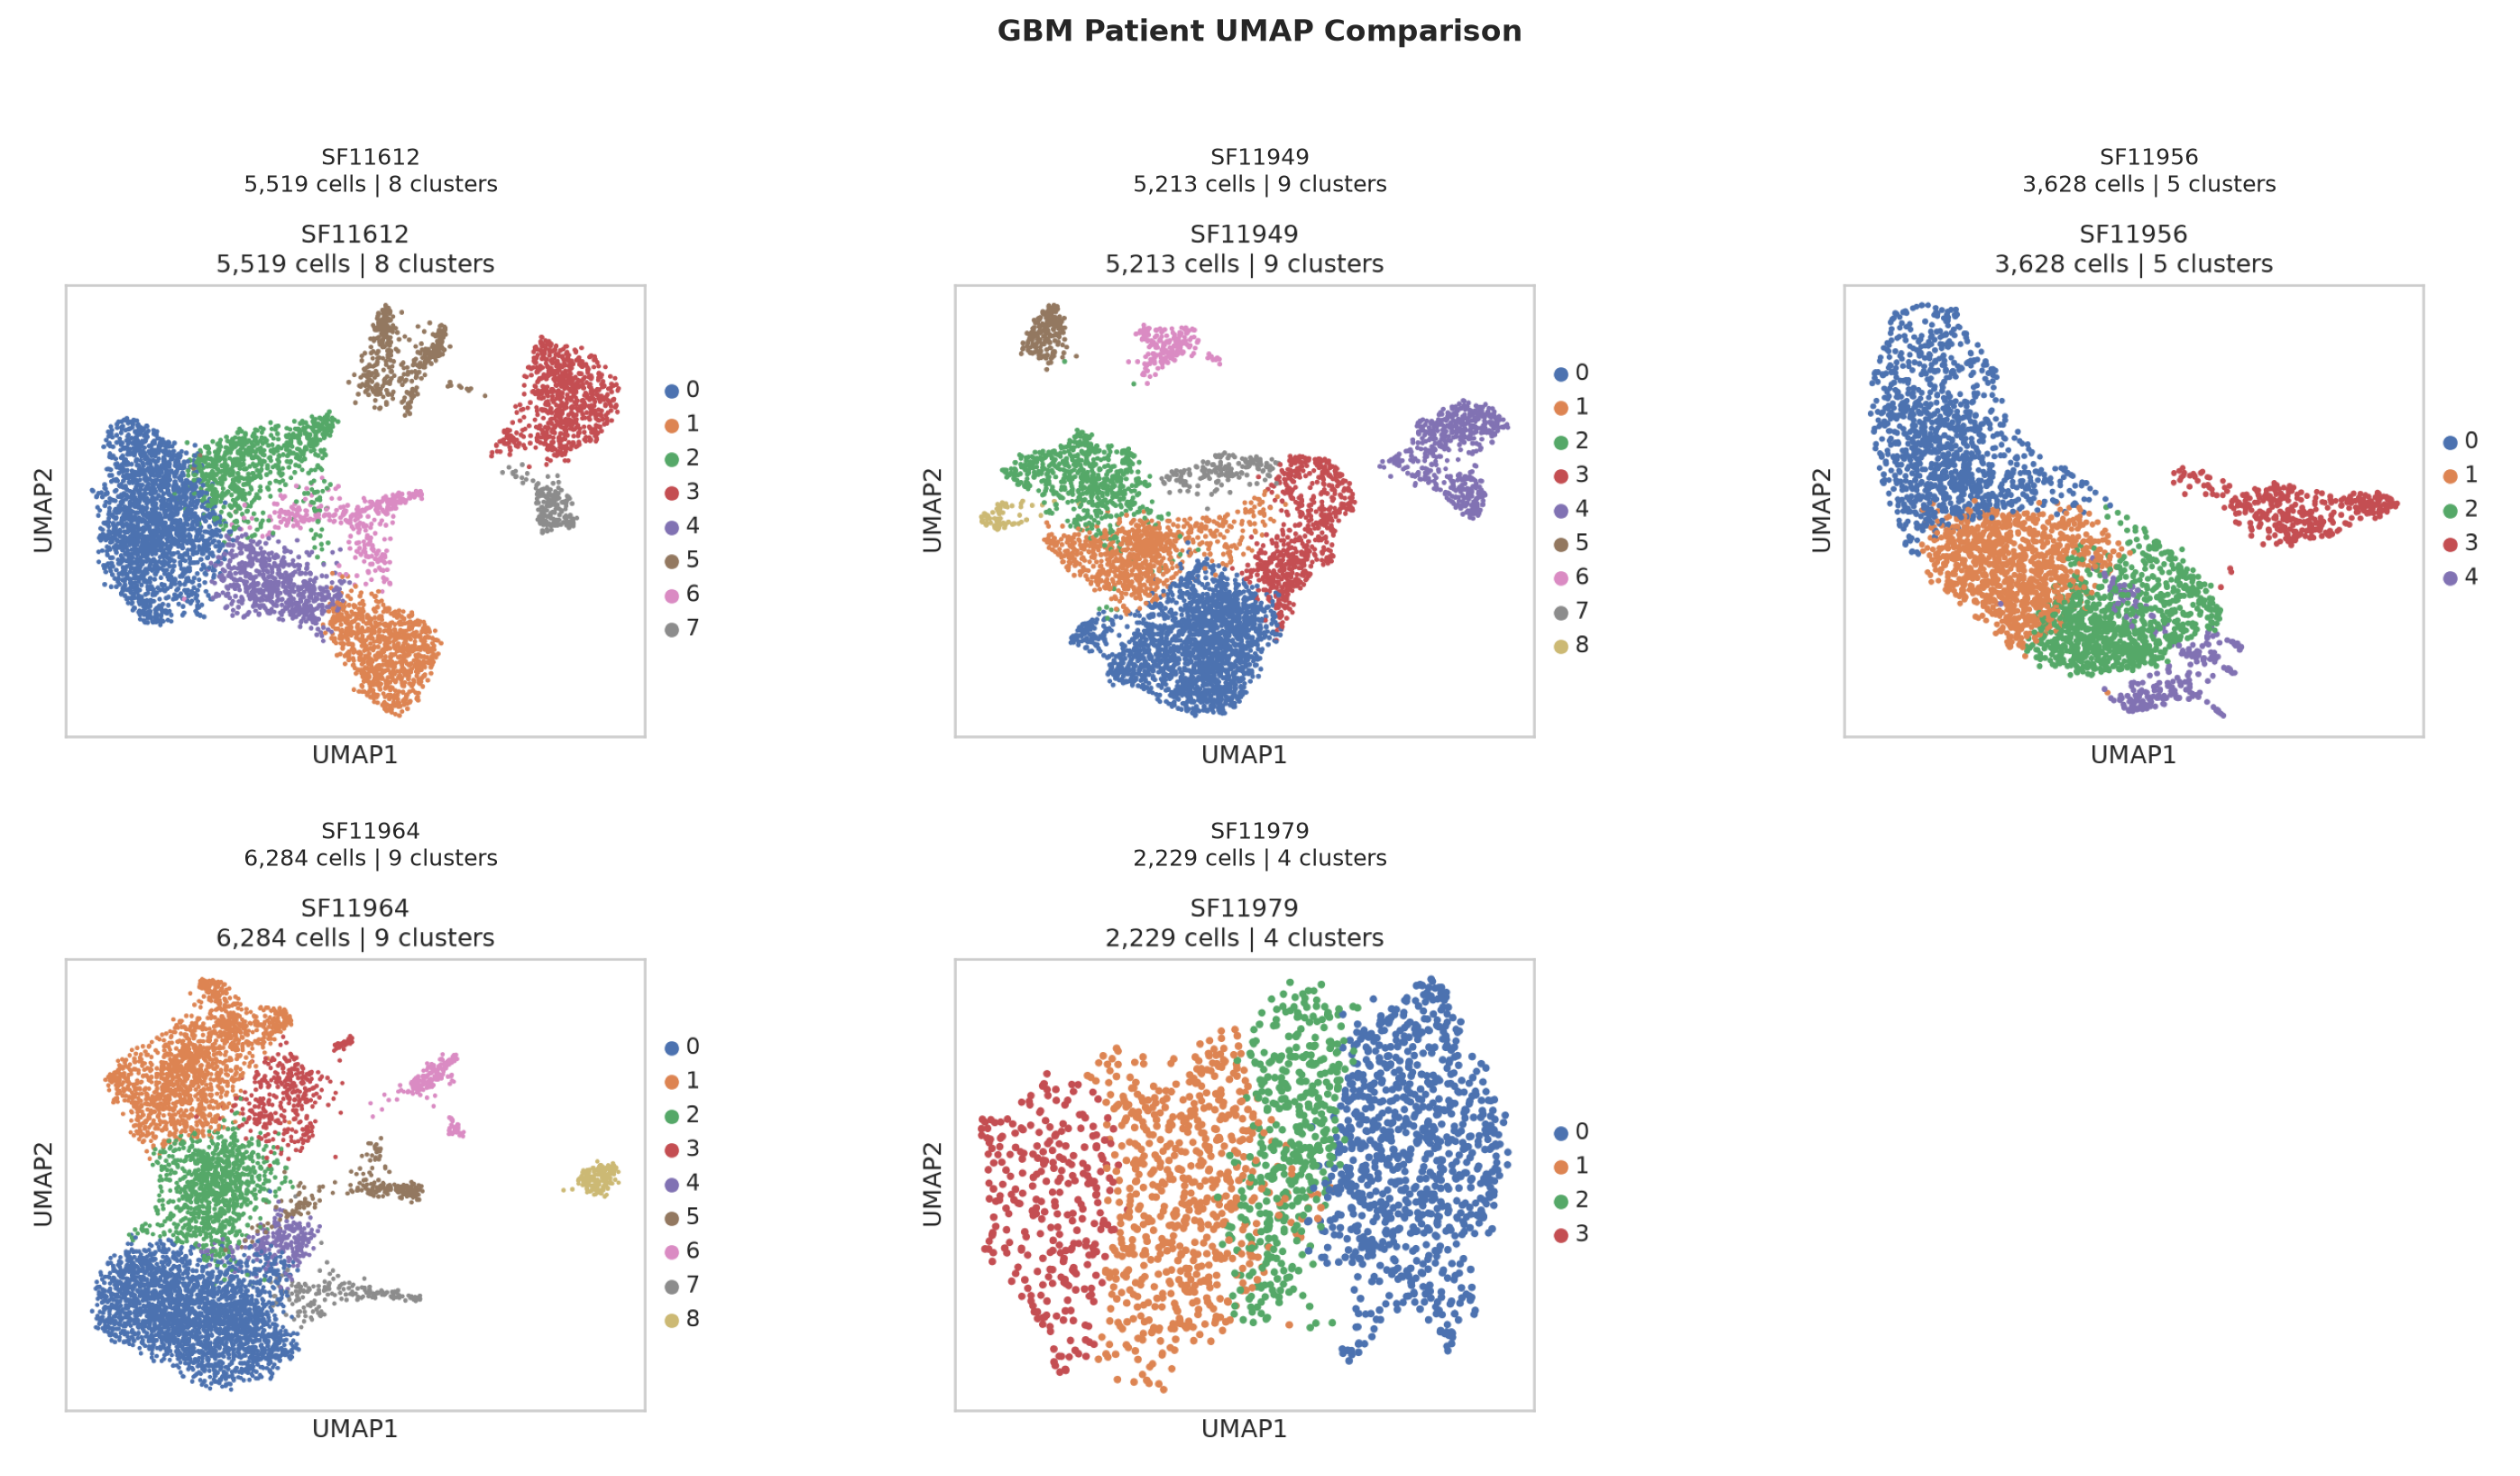


→ Comparison figure saved: /mnt/c/Users/chuab/Desktop/scATACseq/figures/comparison_all_patients.png


In [4]:
from __future__ import annotations

from pathlib import Path
import importlib
import gc
import math
import random
import traceback
import warnings

import numpy as np
import pandas as pd
from scipy import sparse
from scipy.io import mmread
from scipy.stats import norm

import anndata as ad
import scanpy as sc

import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler


# ── Optional imports ──────────────────────────────────────────────────────────
def optional_import(module_name: str):
    try:
        return importlib.import_module(module_name)
    except ImportError:
        print(f"Optional package not installed: {module_name}")
        return None

mu    = optional_import("muon")
snap  = optional_import("snapatac2")
torch = optional_import("torch")


# ── Seeds & paths ─────────────────────────────────────────────────────────────
RANDOM_SEED = 13
np.random.seed(RANDOM_SEED)
random.seed(RANDOM_SEED)

DATA_DIR   = Path("/mnt/c/Users/chuab/Desktop/scATACseq")
FIGURE_DIR = DATA_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, facecolor="white", figsize=(5, 4))
sns.set_theme(style="whitegrid", context="notebook")

print(f"Data directory  : {DATA_DIR}")
print(f"Scanpy version  : {sc.__version__}")
print(f"AnnData version : {ad.__version__}")
print(f"Muon available  : {mu    is not None}")
print(f"SnapATAC2 avail : {snap  is not None}")
print(f"PyTorch avail   : {torch is not None}")


# ── Patient discovery ─────────────────────────────────────────────────────────
ALL_PATIENT_FOLDERS = sorted(DATA_DIR.glob("GSE138794_Glioma_Patient_*"))

if not ALL_PATIENT_FOLDERS:
    raise FileNotFoundError(
        f"No patient folders found in {DATA_DIR}.\n"
        f"Contents: {[p.name for p in DATA_DIR.iterdir()]}"
    )

print(f"\nFound {len(ALL_PATIENT_FOLDERS)} patient folder(s):")
for p in ALL_PATIENT_FOLDERS:
    children = [c.name for c in sorted(p.iterdir())]
    print(f"  {p.name}/  →  {children}")


# ── Select which patients to process ─────────────────────────────────────────
# Option A: single patient (recommended first run to verify pipeline)
# ANALYSIS_PATIENTS = ALL_PATIENT_FOLDERS[:1]

# Option B: two patients
# ANALYSIS_PATIENTS = ALL_PATIENT_FOLDERS[:2]

# Option C: all patients (sequential, one at a time)
ANALYSIS_PATIENTS = ALL_PATIENT_FOLDERS

print(f"\nWill process {len(ANALYSIS_PATIENTS)} patient(s).")


# ── Custom loader for GSE138794 file layout ───────────────────────────────────
def load_patient_data(patient_dir: Path) -> ad.AnnData:
    """
    Reads the three custom-named files used in GSE138794:
      GSE138794_matrix.mtx  : sparse count matrix (peaks × cells)
      GSE138794_barcodes.tsv: cell barcodes
      GSE138794_peaks.tsv   : peak coordinates (chr:start-end)
    Returns AnnData of shape (cells × peaks).
    """
    mtx_file      = patient_dir / "GSE138794_matrix.mtx"
    barcodes_file = patient_dir / "GSE138794_barcodes.tsv"
    peaks_file    = patient_dir / "GSE138794_peaks.tsv"

    for f in [mtx_file, barcodes_file, peaks_file]:
        if not f.exists():
            raise FileNotFoundError(f"Missing expected file: {f}")

    print(f"  [loader] GSE138794 custom MTX  →  {patient_dir.name}/")

    # mmread returns (peaks × cells) COO matrix → transpose to (cells × peaks)
    X        = mmread(str(mtx_file)).T.tocsr()
    barcodes = pd.read_csv(barcodes_file, header=None)[0].tolist()
    peaks    = pd.read_csv(peaks_file,    header=None)[0].tolist()

    print(f"  Raw matrix  (cells × peaks): {X.shape[0]} × {X.shape[1]}")
    print(f"  Barcodes: {len(barcodes)}  |  Peaks: {len(peaks)}")

    # Sanity check dimensions match
    if X.shape[0] != len(barcodes):
        raise ValueError(
            f"Matrix rows ({X.shape[0]}) ≠ barcode count ({len(barcodes)}). "
            "Matrix may not have been transposed correctly."
        )
    if X.shape[1] != len(peaks):
        raise ValueError(
            f"Matrix cols ({X.shape[1]}) ≠ peak count ({len(peaks)}). "
            "Check MTX file orientation."
        )

    adata = ad.AnnData(
        X   = X,
        obs = pd.DataFrame(index=barcodes),
        var = pd.DataFrame(index=peaks),
    )
    return adata


# ── Per-patient processing ────────────────────────────────────────────────────
def process_patient(patient_dir: Path, figure_dir: Path) -> dict:
    patient_id = patient_dir.name
    print(f"\n{'='*60}")
    print(f"  Processing: {patient_id}")
    print(f"{'='*60}")

    # --- Load ---
    adata = load_patient_data(patient_dir)
    adata.obs["patient"] = patient_id
    adata.var_names_make_unique()

    # --- QC: filter low-coverage cells and rarely-accessible peaks ---
    sc.pp.filter_cells(adata, min_genes=200)   # min 200 accessible peaks per cell
    sc.pp.filter_genes(adata, min_cells=3)     # peak accessible in at least 3 cells
    print(f"  After QC filter: {adata.shape}")

    if adata.n_obs < 50:
        raise ValueError(f"Too few cells after QC ({adata.n_obs}). Check input data.")

    # --- TF-IDF normalisation (standard for scATAC-seq) ---
    # log(TF) × log(1 + N/DF)  where N = total cells, DF = cells with peak open
    from sklearn.feature_extraction.text import TfidfTransformer
    tfidf = TfidfTransformer(norm="l2", use_idf=True, smooth_idf=True)
    X_tfidf = tfidf.fit_transform(adata.X)
    adata.X = X_tfidf

    # --- Select top peaks by variance (ATAC equivalent of HVG) ---
    N_TOP_PEAKS = 20_000
    n_top = min(N_TOP_PEAKS, adata.n_vars)
    mean_sq  = np.asarray(adata.X.power(2).mean(axis=0)).flatten()
    sq_mean  = np.asarray(adata.X.mean(axis=0)).flatten() ** 2
    peak_var = mean_sq - sq_mean
    top_idx  = np.argsort(peak_var)[::-1][:n_top]
    adata    = adata[:, top_idx].copy()
    print(f"  Top {n_top} variable peaks selected.")

    # --- LSI (TruncatedSVD): the ATAC equivalent of PCA ---
    N_COMPS = min(50, adata.n_obs - 1, adata.n_vars - 1)
    lsi     = TruncatedSVD(n_components=N_COMPS, random_state=RANDOM_SEED)
    X_lsi   = lsi.fit_transform(adata.X)

    # Drop component 1 (captures sequencing depth, not biology)
    X_lsi = X_lsi[:, 1:]
    adata.obsm["X_lsi"] = X_lsi
    print(f"  LSI done: {X_lsi.shape[1]} components (comp 1 dropped).")

    # --- Neighbors, UMAP, Leiden from LSI embedding ---
    sc.pp.neighbors(adata, use_rep="X_lsi", n_neighbors=15, random_state=RANDOM_SEED)
    sc.tl.umap(adata, random_state=RANDOM_SEED)
    sc.tl.leiden(adata, resolution=0.5, random_state=RANDOM_SEED)

    n_cells    = adata.n_obs
    n_features = adata.n_vars
    n_clusters = adata.obs["leiden"].nunique()
    print(f"  Cells: {n_cells} | Peaks: {n_features} | Leiden clusters: {n_clusters}")

    # --- Save per-patient UMAP ---
    umap_path = figure_dir / f"{patient_id}_umap.png"
    sc.pl.umap(
        adata,
        color="leiden",
        show=False,
        title=f"{patient_id.replace('GSE138794_Glioma_Patient_', '')}\n"
              f"{n_cells:,} cells | {n_clusters} clusters",
    )
    plt.savefig(umap_path, dpi=150, bbox_inches="tight")
    plt.close("all")
    print(f"  → Saved: {umap_path.name}")

    summary = {
        "patient_id": patient_id,
        "n_cells":    n_cells,
        "n_peaks":    n_features,
        "n_clusters": n_clusters,
        "umap_path":  umap_path,
    }

    del adata
    gc.collect()
    return summary


# ── Sequential patient loop ───────────────────────────────────────────────────
results = {}

for patient_dir in ANALYSIS_PATIENTS:
    try:
        summary = process_patient(patient_dir, FIGURE_DIR)
        results[summary["patient_id"]] = summary
    except Exception:
        print(f"\n  [ERROR] Failed on {patient_dir.name}:")
        traceback.print_exc()
        gc.collect()
        continue

print(f"\n✓ Done. Processed {len(results)} / {len(ANALYSIS_PATIENTS)} patient(s).")


# ── Summary table ─────────────────────────────────────────────────────────────
if not results:
    print("\n[!] No patients completed. Check errors above.")
else:
    summary_df = (
        pd.DataFrame(list(results.values()))
          .set_index("patient_id")
    )
    print("\n── Per-patient summary ──────────────────────────────")
    print(summary_df[["n_cells", "n_peaks", "n_clusters"]].to_string())


# ── Side-by-side UMAP comparison ──────────────────────────────────────────────
n = len(results)
if n > 0:
    ncols = min(n, 3)
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                             squeeze=False)
    axes = axes.flatten()

    for ax, (pid, info) in zip(axes, results.items()):
        img = mpimg.imread(info["umap_path"])
        ax.imshow(img)
        short_id = pid.replace("GSE138794_Glioma_Patient_", "")
        ax.set_title(
            f"{short_id}\n{info['n_cells']:,} cells | {info['n_clusters']} clusters",
            fontsize=9,
        )
        ax.axis("off")

    for ax in axes[n:]:
        ax.set_visible(False)

    plt.suptitle("GBM Patient UMAP Comparison", fontsize=12, fontweight="bold", y=1.02)
    plt.tight_layout()

    comparison_path = FIGURE_DIR / "comparison_all_patients.png"
    plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"\n→ Comparison figure saved: {comparison_path}")

## Project setup and goals

The goal is to build a transparent Python analysis that mirrors the logic of established scATAC workflows.

The main analysis path is:

1. Load exported Matrix Market peak matrices for one or more glioblastoma patients.
2. Compute cell and peak quality metrics.
3. Filter low quality cells and rare peaks.
4. Apply TF IDF normalization, where peaks behave like words and cells behave like documents.
5. Compute SVD on the TF IDF matrix to obtain LSI components.
6. Run UMAP and t SNE on the LSI space rather than on raw counts.
7. Cluster cells in the LSI graph and interpret clusters with gene activity scores.
8. Test differential peak accessibility and sketch motif enrichment.
9. Explore classical machine learning and a small deep learning autoencoder.
10. Connect the Python workflow to parallel ArchR and SnapATAC2 workflows.

Method choice, TF IDF plus SVD is preferred because scATAC data are highly sparse and peak counts are strongly affected by sequencing depth. PCA on log normalized counts is included only as a comparison because it is common in scRNA seq, not because it is the strongest choice for peak accessibility.


## Methods overview

The workflow uses TF IDF normalization followed by LSI as the main representation. This is the standard choice for sparse scATAC peak matrices because it reduces the influence of sequencing depth and very common peaks.

UMAP and t SNE are then used only for visualization. Clustering is performed on a nearest neighbor graph built from LSI components, and downstream interpretation uses gene activity and differential peak accessibility.


# Data loading and organization

Each patient folder contains a Matrix Market file, a barcode table, and a peak table. The exported matrix is peak by cell, but AnnData expects observations by variables, so the loader transposes the matrix into cell by peak orientation. Cells are stored in `.obs`, peaks are stored in `.var`, and patient identity is stored as a categorical covariate.

Option A uses one patient to study intra tumor heterogeneity. This is the default because it is fast and memory friendly.

Option B concatenates multiple patients to study cross patient cell states, tumor microenvironment compartments, and patient batch effects.


In [ ]:
PATIENT_FOLDERS = [
    "GSE138794_Glioma_Patient_SF11964",
    "GSE138794_Glioma_Patient_SF12017",
    "GSE138794_Glioma_Patient_SF11949",
    "GSE138794_Glioma_Patient_SF11612",
    "GSE138794_Glioma_Patient_SF11979",
    "GSE138794_Glioma_Patient_SF11956",
]

TEST_PATIENT = "Glioma_Patient_SF11979"


# ---------- Patient discovery helpers ----------

def discover_patient_folders(base_dir: Path) -> list[str]:
    """Return patient folders that match the naming used by the scATAC.Explorer export."""
    return sorted(
        path.name
        for path in Path(base_dir).glob("GSE138794_Glioma_Patient_*")
        if path.is_dir()
    )


def find_patient_dir(base_dir: Path, patient_name: str) -> Path:
    """Resolve patient names with or without the GSE prefix."""
    base_dir = Path(base_dir)
    candidates = [
        base_dir / patient_name,
        base_dir / f"GSE138794_{patient_name}",
        base_dir / f"GSE138794_Glioma_Patient_{patient_name}",
    ]
    for candidate in candidates:
        if candidate.exists():
            return candidate

    matches = sorted(base_dir.glob(f"*{patient_name}*"))
    matches = [match for match in matches if match.is_dir()]
    if len(matches) == 1:
        return matches[0]
    if len(matches) > 1:
        raise FileExistsError(
            f"Patient name {patient_name!r} matched multiple folders: {matches}"
        )
    raise FileNotFoundError(
        f"Could not find a folder for patient {patient_name!r} under {base_dir}"
    )


def find_first_file(folder: Path, patterns: list[str]) -> Path:
    """Find the first file matching a list of glob patterns."""
    for pattern in patterns:
        matches = sorted(Path(folder).glob(pattern))
        matches = [match for match in matches if match.is_file()]
        if matches:
            return matches[0]
    raise FileNotFoundError(f"No file matching {patterns} found in {folder}")


def read_first_column(path: Path) -> pd.Series:
    """Read a one column TSV style file while tolerating extra columns."""
    table = pd.read_csv(path, sep="\t", header=None, comment="#")
    return table.iloc[:, 0].astype(str)


def parse_peak_table(path: Path) -> pd.DataFrame:
    """Parse peak coordinates from chr-start-end or BED like peak tables."""
    table = pd.read_csv(path, sep="\t", header=None, comment="#")

    if table.shape[1] >= 3:
        chrom = table.iloc[:, 0].astype(str)
        start = pd.to_numeric(table.iloc[:, 1], errors="coerce")
        end = pd.to_numeric(table.iloc[:, 2], errors="coerce")
        peak_id = (
            chrom
            + "-"
            + start.astype("Int64").astype(str)
            + "-"
            + end.astype("Int64").astype(str)
        )
    else:
        peak_id = table.iloc[:, 0].astype(str)
        parsed = peak_id.str.extract(
            r"^(?P<chrom>[^:\-]+)[:-](?P<start>\d+)[:-](?P<end>\d+)$"
        )
        chrom = parsed["chrom"]
        start = pd.to_numeric(parsed["start"], errors="coerce")
        end = pd.to_numeric(parsed["end"], errors="coerce")

    peaks = pd.DataFrame(
        {
            "peak_id": peak_id.astype(str).to_numpy(),
            "chrom": chrom.astype(str).to_numpy(),
            "start": start.to_numpy(),
            "end": end.to_numpy(),
        }
    )
    peaks["width"] = peaks["end"] - peaks["start"]
    return peaks


def load_patient_mtx(base_dir: Path, patient_name: str) -> ad.AnnData:
    """
    Load one Matrix Market scATAC export into AnnData.

    The input matrix is expected to be peak by cell.
    The returned AnnData follows the standard convention, cells by peaks.
    """
    patient_dir = find_patient_dir(base_dir, patient_name)
    patient_label = patient_dir.name.replace("GSE138794_", "")

    matrix_path = find_first_file(patient_dir, ["*matrix*.mtx", "*.mtx", "*.mtx.gz"])
    barcode_path = find_first_file(
        patient_dir, ["*barcode*.tsv", "*barcodes*.tsv", "*cell*.tsv"]
    )
    peak_path = find_first_file(
        patient_dir, ["*peak*.tsv", "*peaks*.tsv", "*feature*.tsv", "*features*.tsv"]
    )

    barcodes = read_first_column(barcode_path)
    peaks = parse_peak_table(peak_path)
    raw = mmread(matrix_path).tocsr()

    if raw.shape == (len(peaks), len(barcodes)):
        X = raw.T.tocsr()
    elif raw.shape == (len(barcodes), len(peaks)):
        X = raw.tocsr()
    else:
        raise ValueError(
            "Matrix dimensions do not match barcode and peak files. "
            f"Matrix shape: {raw.shape}, barcodes: {len(barcodes)}, peaks: {len(peaks)}"
        )

    obs = pd.DataFrame(index=[f"{patient_label}:{barcode}" for barcode in barcodes])
    obs["barcode"] = barcodes.to_numpy()
    obs["patient"] = patient_label
    obs["patient"] = obs["patient"].astype("category")

    var = peaks.copy()
    var.index = var["peak_id"].astype(str)

    adata = ad.AnnData(X=X, obs=obs, var=var)
    adata.var_names_make_unique()
    adata.uns["patient_label"] = patient_label
    adata.uns["source_files"] = {
        "patient_dir": str(patient_dir),
        "matrix": str(matrix_path),
        "barcodes": str(barcode_path),
        "peaks": str(peak_path),
    }
    return adata


def matrix_sparsity(X) -> float:
    """Return the fraction of matrix entries that are zero."""
    nnz = X.nnz if sparse.issparse(X) else np.count_nonzero(X)
    return 1.0 - nnz / (X.shape[0] * X.shape[1])


def print_basic_summary(adata: ad.AnnData, label: str = "AnnData") -> None:
    """Print a compact summary for a loaded scATAC matrix."""
    print(f"{label}")
    print(f"  cells: {adata.n_obs:,}")
    print(f"  peaks: {adata.n_vars:,}")
    print(
        f"  nonzero entries: "
        f"{adata.X.nnz if sparse.issparse(adata.X) else np.count_nonzero(adata.X):,}"
    )
    print(f"  sparsity: {matrix_sparsity(adata.X):.4f}")
    print(f"  patients: {list(adata.obs['patient'].cat.categories)}")


def concatenate_patients(adatas: list[ad.AnnData]) -> ad.AnnData:
    """Concatenate patient AnnData objects, aligning peaks by genomic peak name."""
    if len(adatas) == 1:
        return adatas[0].copy()
    combined = ad.concat(
        adatas,
        axis=0,
        join="outer",
        merge="first",
        fill_value=0,
        index_unique=None,
    )
    combined.obs["patient"] = combined.obs["patient"].astype("category")
    combined.var_names_make_unique()
    return combined


# ---------- Choose patients for this run ----------

available_patients = discover_patient_folders(DATA_DIR)
print("Available patient folders:")
for patient in available_patients:
    print(f"  {patient}")

# SINGLE-PATIENT MODE (comment this line when running multi-patient)
# ANALYSIS_PATIENTS = [TEST_PATIENT]

# MULTI-PATIENT MODE (current default): analyze all discovered patients
ANALYSIS_PATIENTS = available_patients

analysis_patient_categories = [
    find_patient_dir(DATA_DIR, patient).name.replace("GSE138794_", "")
    for patient in ANALYSIS_PATIENTS
]
print("Analysis patients:")
for patient in analysis_patient_categories:
    print(f"  {patient}")

# Load one test patient for a quick sanity check
adata_test = load_patient_mtx(DATA_DIR, TEST_PATIENT)
print_basic_summary(adata_test, label=f"Initial test patient: {TEST_PATIENT}")

# Load analysis patients
if ANALYSIS_PATIENTS == [TEST_PATIENT]:
    adatas = [adata_test]
else:
    adatas = [load_patient_mtx(DATA_DIR, patient) for patient in ANALYSIS_PATIENTS]

adata_raw = concatenate_patients(adatas)
adata_raw.obs["patient"] = pd.Categorical(
    adata_raw.obs["patient"].astype(str),
    categories=analysis_patient_categories,
)
print_basic_summary(adata_raw, label="Raw analysis object")

# Classical scATAC preprocessing

The preprocessing block mirrors the core logic of scATAC workflows.

Cell QC focuses on library complexity, total fragments in peaks, and the number of accessible peaks per cell. With fragment files, one would also compute TSS enrichment and FRIP. Here the available input is already a peak matrix, so the complexity metrics are matrix based proxies.

Peak QC removes peaks that are detected in too few cells. Rare peaks can be biologically meaningful, but very rare features add noise and make SVD unstable.

TF IDF weighting is used because cells are analogous to documents and peaks are analogous to words. A peak that is frequent in one cell but rare across all cells is informative. A peak that is open almost everywhere is less informative for separating cell states.

Method A is TF IDF plus SVD, also called LSI for scATAC, preferred for sparse accessibility data. Method B is PCA on log normalized counts, which is common in scRNA seq and not ideal here. This notebook chooses Method A for the main analysis and keeps Method B as a comparison.


## Results, QC and TF IDF methods

TF IDF normalization is used because scATAC counts are very sparse. It treats peaks like words and cells like documents, which is useful because some peaks are broadly open while others are specific to certain cells.

TF means term frequency, which here measures how strongly a peak is represented within one cell after accounting for that cell's total fragments. IDF means inverse document frequency, which downweights peaks that are open in many cells and upweights peaks that are more specific.

We use TF IDF instead of simple log normalization because scATAC data contain many zeros and strong depth differences. This makes TF IDF a better match for accessibility data than the normalization steps often used for scRNA seq.


In [ ]:
def compute_qc_metrics(adata: ad.AnnData) -> ad.AnnData:
    """Compute matrix based QC metrics for cells and peaks."""
    X = adata.X.tocsr() if sparse.issparse(adata.X) else sparse.csr_matrix(adata.X)

    total_fragments = np.asarray(X.sum(axis=1)).ravel()
    n_peaks_by_counts = np.asarray(X.getnnz(axis=1)).ravel()
    peak_total_counts = np.asarray(X.sum(axis=0)).ravel()
    peak_n_cells = np.asarray(X.getnnz(axis=0)).ravel()

    adata.obs["total_fragments"] = total_fragments
    adata.obs["n_peaks_by_counts"] = n_peaks_by_counts
    adata.obs["log10_fragments"] = np.log10(total_fragments + 1)
    adata.obs["log10_peaks"] = np.log10(n_peaks_by_counts + 1)
    adata.obs["complexity_proxy"] = n_peaks_by_counts / np.maximum(total_fragments, 1)

    adata.var["total_counts"] = peak_total_counts
    adata.var["n_cells"] = peak_n_cells
    adata.var["frac_cells"] = peak_n_cells / max(adata.n_obs, 1)
    return adata


def choose_qc_thresholds(
    adata: ad.AnnData,
    min_fragments_floor: int = 500,
    min_peaks_floor: int = 250,
    lower_quantile: float = 0.01,
    upper_quantile: float = 0.995,
    min_peak_cells: int = 5,
) -> dict[str, float]:
    """Choose conservative adaptive QC thresholds for peak matrix data."""
    obs = adata.obs

    def adaptive_lower(column: str, floor: int) -> float:
        values = obs[column].to_numpy()
        median = float(np.nanmedian(values))
        lower = float(np.nanquantile(values, lower_quantile))
        if median < floor:
            return max(1.0, lower)
        return max(float(floor), lower)

    min_fragments = adaptive_lower("total_fragments", min_fragments_floor)
    min_peaks = adaptive_lower("n_peaks_by_counts", min_peaks_floor)
    max_fragments = float(np.nanquantile(obs["total_fragments"], upper_quantile))
    max_peaks = float(np.nanquantile(obs["n_peaks_by_counts"], upper_quantile))

    if max_fragments <= min_fragments:
        max_fragments = float("inf")
    if max_peaks <= min_peaks:
        max_peaks = float("inf")

    return {
        "min_fragments": min_fragments,
        "max_fragments": max_fragments,
        "min_peaks": min_peaks,
        "max_peaks": max_peaks,
        "min_peak_cells": min_peak_cells,
    }


def plot_qc_metrics(adata: ad.AnnData, label: str = "before QC", filename: str | None = None) -> None:
    """Plot the main cell QC distributions."""
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    sns.histplot(adata.obs["log10_fragments"], bins=50, ax=axes[0, 0])
    axes[0, 0].set_title(f"log10 fragments per cell, {label}")
    axes[0, 0].set_xlabel("log10(total fragments + 1)")

    sns.histplot(adata.obs["log10_peaks"], bins=50, ax=axes[0, 1])
    axes[0, 1].set_title(f"log10 accessible peaks per cell, {label}")
    axes[0, 1].set_xlabel("log10(nonzero peaks + 1)")

    sns.violinplot(y=adata.obs["complexity_proxy"], ax=axes[1, 0], color="lightsteelblue")
    axes[1, 0].set_title(f"complexity proxy, {label}")
    axes[1, 0].set_ylabel("nonzero peaks / fragments")

    sns.histplot(adata.var["n_cells"], bins=50, ax=axes[1, 1])
    axes[1, 1].set_title(f"cells per peak, {label}")
    axes[1, 1].set_xlabel("number of cells with nonzero accessibility")

    plt.tight_layout()
    if filename is not None:
        fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


def filter_cells_and_peaks(adata: ad.AnnData, thresholds: dict[str, float]) -> ad.AnnData:
    """Filter low quality cells and rarely accessible peaks."""
    obs = adata.obs
    cell_mask = (
        (obs["total_fragments"] >= thresholds["min_fragments"])
        & (obs["total_fragments"] <= thresholds["max_fragments"])
        & (obs["n_peaks_by_counts"] >= thresholds["min_peaks"])
        & (obs["n_peaks_by_counts"] <= thresholds["max_peaks"])
    )

    if int(cell_mask.sum()) < 10:
        warnings.warn("QC thresholds kept fewer than 10 cells, relaxing upper cutoffs.")
        cell_mask = (
            (obs["total_fragments"] >= thresholds["min_fragments"])
            & (obs["n_peaks_by_counts"] >= thresholds["min_peaks"])
        )

    if int(cell_mask.sum()) == 0:
        raise ValueError("QC thresholds removed all cells. Inspect the QC distributions and relax thresholds.")

    peak_mask = adata.var["n_cells"] >= thresholds["min_peak_cells"]
    if int(peak_mask.sum()) == 0:
        raise ValueError("Peak filtering removed all peaks. Lower min_peak_cells.")

    filtered = adata[cell_mask.to_numpy(), peak_mask.to_numpy()].copy()
    filtered.uns["filtering_summary"] = {
        "cells_before": int(adata.n_obs),
        "cells_after": int(filtered.n_obs),
        "peaks_before": int(adata.n_vars),
        "peaks_after": int(filtered.n_vars),
        **thresholds,
    }
    compute_qc_metrics(filtered)
    return filtered


def tf_idf_transform(
    adata: ad.AnnData,
    layer_key: str = "tfidf",
    scale_factor: float = 1e4,
    log_tf_idf: bool = True,
) -> ad.AnnData:
    """Compute TF IDF weights for a sparse cells by peaks matrix."""
    X = adata.X.tocsr().astype(np.float32) if sparse.issparse(adata.X) else sparse.csr_matrix(adata.X, dtype=np.float32)

    cell_sums = np.asarray(X.sum(axis=1)).ravel()
    inv_cell_sums = np.divide(1.0, cell_sums, out=np.zeros_like(cell_sums, dtype=np.float32), where=cell_sums > 0)
    tf = sparse.diags(inv_cell_sums).dot(X)
    tf = tf.multiply(scale_factor)

    document_frequency = np.asarray(X.getnnz(axis=0)).ravel()
    idf = np.log1p(adata.n_obs / np.maximum(document_frequency, 1))
    tfidf = tf.multiply(idf).tocsr()

    if log_tf_idf:
        tfidf.data = np.log1p(tfidf.data)

    adata.layers[layer_key] = tfidf
    adata.var["idf"] = idf
    adata.uns["tfidf"] = {
        "layer_key": layer_key,
        "scale_factor": scale_factor,
        "log_tf_idf": log_tf_idf,
    }
    return adata


def compute_lsi(
    adata: ad.AnnData,
    n_components: int = 50,
    layer_key: str = "tfidf",
    drop_first: bool = True,
    scale_embedding: bool = True,
    random_state: int = RANDOM_SEED,
) -> ad.AnnData:
    """Run truncated SVD on the TF IDF matrix and store LSI components."""
    X = adata.layers[layer_key] if layer_key in adata.layers else adata.X
    max_components = min(X.shape) - 1
    if max_components < 2:
        raise ValueError("Not enough cells or peaks for SVD.")

    requested = n_components + int(drop_first)
    effective_components = min(requested, max_components)
    svd = TruncatedSVD(n_components=effective_components, random_state=random_state)
    embedding = svd.fit_transform(X)

    if scale_embedding:
        embedding = StandardScaler(with_mean=True, with_std=True).fit_transform(embedding)

    adata.obsm["X_lsi_full"] = embedding
    if drop_first and embedding.shape[1] > 1:
        adata.obsm["X_lsi"] = embedding[:, 1:]
    else:
        adata.obsm["X_lsi"] = embedding

    adata.uns["lsi"] = {
        "n_components_requested": n_components,
        "n_components_used": int(adata.obsm["X_lsi"].shape[1]),
        "drop_first": drop_first,
        "explained_variance_ratio": svd.explained_variance_ratio_.tolist(),
        "singular_values": svd.singular_values_.tolist(),
    }
    return adata


adata_raw = compute_qc_metrics(adata_raw)
plot_qc_metrics(adata_raw, label="before QC", filename="qc_distributions_before_filtering.png")

qc_thresholds = choose_qc_thresholds(adata_raw, min_peak_cells=5)
print("QC thresholds:")
for key, value in qc_thresholds.items():
    print(f"  {key}: {value}")

adata_pre_qc = adata_raw.copy()
adata = filter_cells_and_peaks(adata_raw, qc_thresholds)
print_basic_summary(adata, label="Filtered analysis object")
plot_qc_metrics(adata, label="after QC", filename="qc_distributions_after_filtering.png")

N_LSI_COMPONENTS = 50
adata = tf_idf_transform(adata, layer_key="tfidf")
adata = compute_lsi(adata, n_components=N_LSI_COMPONENTS, layer_key="tfidf", drop_first=True)
print(f"LSI shape after dropping first component: {adata.obsm['X_lsi'].shape}")


### QC Figure Interpretation

The QC panels show the distribution of total fragments per cell, the number of accessible peaks per cell, a simple complexity proxy, and the number of cells supporting each peak. In this run, the matrix started with 2,229 cells and 40,907 peaks.

After QC, 2,187 cells and 39,352 peaks were retained. This means 42 cells and 1,555 peaks were filtered out, which is a modest filter that removes the weakest profiles and rare peaks without discarding most of the sample.

The chosen thresholds make sense because the removed cells are at the low depth or low complexity edge of the distributions. Keeping the stronger profiles gives more confidence that later UMAP structure reflects chromatin biology rather than empty or damaged nuclei.


# Dimensionality reduction and visualization

UMAP and t SNE are visualization methods, not the primary statistical normalization. In this workflow they are run on the low dimensional LSI coordinates, not on the raw high dimensional peak matrix.

UMAP vs t SNE, UMAP usually preserves more global neighborhood relationships and is faster for exploratory scATAC maps. t SNE can make local groups visually crisp, but distances between far apart groups are harder to interpret. Both depend on the upstream LSI representation.

LSI vs PCA, LSI starts from TF IDF weighted accessibility and handles sparse binary like peak data better. PCA on log normalized counts is included as a sanity comparison because it is familiar from scRNA seq.


## Results, Embeddings and Visualization Methods

LSI means latent semantic indexing. In this workflow it is SVD, singular value decomposition, applied to the TF IDF matrix. The result is a compact set of components that summarize each cell's accessibility profile.

LSI is preferred over plain PCA on counts because peak accessibility is sparse and binary like. PCA on raw or log normalized counts is more sensitive to depth and broadly accessible peaks, while LSI better captures regulatory differences between cells.

UMAP and t SNE take the LSI components as input and draw two dimensional maps. UMAP tries to preserve local neighborhoods while retaining some global structure, while t SNE focuses more strongly on local neighborhoods. Both are applied to LSI, not to raw peaks, because raw peak space is too high dimensional and sparse.


In [ ]:
def run_neighbors_umap_tsne(
    adata: ad.AnnData,
    use_rep: str = "X_lsi",
    n_neighbors: int = 30,
    min_dist: float = 0.35,
    metric: str = "cosine",
    run_tsne: bool = True,
    random_state: int = RANDOM_SEED,
) -> ad.AnnData:
    """Build a neighbor graph, run UMAP, and optionally run t SNE."""
    n_neighbors = min(n_neighbors, max(2, adata.n_obs - 1))
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, use_rep=use_rep, metric=metric, random_state=random_state)
    sc.tl.umap(adata, min_dist=min_dist, random_state=random_state)

    if run_tsne and adata.n_obs > 10:
        perplexity = min(30, max(5, (adata.n_obs - 1) // 3))
        try:
            tsne = TSNE(
                n_components=2,
                perplexity=perplexity,
                init="pca",
                learning_rate="auto",
                max_iter=1000,
                random_state=random_state,
            )
        except TypeError:
            tsne = TSNE(
                n_components=2,
                perplexity=perplexity,
                init="pca",
                learning_rate="auto",
                n_iter=1000,
                random_state=random_state,
            )
        adata.obsm["X_tsne"] = tsne.fit_transform(adata.obsm[use_rep])

    return adata


def plot_embedding_grid(
    adata: ad.AnnData,
    basis: str,
    color_cols: list[str],
    ncols: int = 2,
    point_size: float = 7,
    title_prefix: str | None = None,
    filename: str | None = None,
) -> None:
    """Plot an embedding colored by categorical or continuous variables."""
    if basis not in adata.obsm:
        print(f"Embedding {basis!r} is not present.")
        return

    coords = np.asarray(adata.obsm[basis])
    ncols = min(ncols, len(color_cols))
    nrows = math.ceil(len(color_cols) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.5 * ncols, 4.8 * nrows), squeeze=False)

    for ax, color in zip(axes.ravel(), color_cols):
        if color not in adata.obs:
            ax.axis("off")
            ax.set_title(f"{color} missing")
            continue

        values = adata.obs[color]
        title = f"{basis} colored by {color}" if title_prefix is None else f"{title_prefix}: {color}"

        if pd.api.types.is_numeric_dtype(values) and values.nunique(dropna=True) > 10:
            scatter = ax.scatter(coords[:, 0], coords[:, 1], c=values.to_numpy(), s=point_size, cmap="viridis", linewidths=0)
            fig.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04)
        else:
            plot_df = pd.DataFrame({"dim1": coords[:, 0], "dim2": coords[:, 1], "color": values.astype(str).to_numpy()})
            sns.scatterplot(
                data=plot_df,
                x="dim1",
                y="dim2",
                hue="color",
                s=point_size,
                linewidth=0,
                ax=ax,
                legend="full",
            )
            ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), title=color, frameon=False)

        ax.set_title(title)
        ax.set_xlabel(f"{basis} 1")
        ax.set_ylabel(f"{basis} 2")

    for ax in axes.ravel()[len(color_cols):]:
        ax.axis("off")

    plt.tight_layout()
    if filename is not None:
        fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


def compute_log_count_pca(adata: ad.AnnData, n_components: int = 30) -> ad.AnnData:
    """Compute PCA on log normalized counts for comparison with LSI."""
    tmp = adata.copy()
    sc.pp.normalize_total(tmp, target_sum=1e4)
    sc.pp.log1p(tmp)
    n_comps = min(n_components, tmp.n_obs - 1, tmp.n_vars - 1)
    sc.pp.pca(tmp, n_comps=n_comps, random_state=RANDOM_SEED)
    adata.obsm["X_pca_counts"] = tmp.obsm["X_pca"]
    adata.uns["pca_counts_variance_ratio"] = tmp.uns["pca"]["variance_ratio"].tolist()
    return adata


def run_umap_from_rep(
    adata: ad.AnnData,
    rep_key: str,
    out_key: str,
    n_neighbors: int = 30,
    metric: str = "cosine",
    random_state: int = RANDOM_SEED,
) -> ad.AnnData:
    """Run UMAP from an arbitrary representation without replacing the main graph."""
    tmp = ad.AnnData(X=sparse.csr_matrix((adata.n_obs, 1)), obs=adata.obs.copy())
    tmp.obsm[rep_key] = np.asarray(adata.obsm[rep_key])
    sc.pp.neighbors(tmp, n_neighbors=min(n_neighbors, max(2, tmp.n_obs - 1)), use_rep=rep_key, metric=metric)
    sc.tl.umap(tmp, random_state=random_state)
    adata.obsm[out_key] = tmp.obsm["X_umap"]
    return adata


adata = run_neighbors_umap_tsne(adata, use_rep="X_lsi", run_tsne=True)
plot_embedding_grid(
    adata,
    basis="X_umap",
    color_cols=["patient", "total_fragments", "n_peaks_by_counts", "complexity_proxy"],
    title_prefix="LSI UMAP",
    filename="umap_lsi_qc_metrics.png",
)

if "X_tsne" in adata.obsm:
    plot_embedding_grid(
        adata,
        basis="X_tsne",
        color_cols=["patient", "total_fragments"],
        title_prefix="LSI t SNE",
        filename="tsne_lsi_patient_qc.png",
    )

adata = compute_log_count_pca(adata, n_components=30)
adata = run_umap_from_rep(adata, rep_key="X_pca_counts", out_key="X_umap_pca_counts", metric="euclidean")
plot_embedding_grid(
    adata,
    basis="X_umap_pca_counts",
    color_cols=["patient", "total_fragments"],
    title_prefix="Log count PCA UMAP comparison",
    filename="pca_umap_comparison.png",
)


### LSI UMAP, t SNE, and PCA Comparison Interpretation

The LSI UMAP shows how cells organize after TF IDF and SVD. Coloring by patient and QC metrics helps separate biological structure from technical effects, for example whether high fragment cells occupy one region or whether patient identity dominates the map.

The t SNE panel provides a second view of the same LSI space. If local groups appear in both UMAP and t SNE, that supports the idea that the structure is present in the embedding rather than produced by one visualization method.

The PCA based UMAP is included as a comparison. If it is less organized or more aligned with depth, that supports using LSI as the primary scATAC representation because PCA on log counts is not designed for sparse peak accessibility matrices.


# Clustering and cell state annotation strategy

Clustering is done on a k nearest neighbor graph built from LSI coordinates. This is analogous to scRNA seq clustering on PCA coordinates, but the upstream representation is scATAC specific.

A useful first diagnostic is to compare UMAP colored by cluster and by patient. If clusters are mostly patient specific, batch or patient effects may dominate. If clusters contain mixed patients, they are more likely to reflect shared cell states, although tumor private states can still be real.

Cell state annotation in scATAC usually proceeds through gene activity scores. Accessibility around promoters and gene bodies is used as a proxy for expression. For glioblastoma, useful marker sets include tumor programs such as EGFR, PDGFRA, SOX2, OLIG2, and NES, astrocyte markers such as GFAP and AQP4, oligodendrocyte lineage markers such as SOX10 and CSPG4, myeloid markers such as PTPRC, AIF1, and CSF1R, endothelial markers such as PECAM1 and VWF, and cycling markers such as MKI67 and TOP2A.


## Results, Clustering Methods

Clustering uses a k nearest neighbor graph built from LSI components. Cells are connected to other cells with similar accessibility profiles, and Leiden or Louvain clustering then groups densely connected cells.

This approach is similar in spirit to scRNA seq clustering, but the input representation is different. For scATAC data, the graph is built from TF IDF and LSI rather than from PCA on gene expression counts.


In [ ]:
def cluster_cells(
    adata: ad.AnnData,
    resolution: float = 0.6,
    key_added: str = "cluster",
    random_state: int = RANDOM_SEED,
) -> ad.AnnData:
    """Cluster cells with Leiden, Louvain, or a KMeans fallback."""
    if "neighbors" not in adata.uns:
        sc.pp.neighbors(
            adata,
            use_rep="X_lsi",
            n_neighbors=min(30, max(2, adata.n_obs - 1)),
            metric="cosine",
        )

    try:
        sc.tl.leiden(
            adata,
            resolution=resolution,
            key_added=key_added,
            random_state=random_state,
        )
        method = "leiden"
    except Exception as leiden_error:
        print(f"Leiden clustering failed, trying Louvain. Reason: {leiden_error}")
        try:
            sc.tl.louvain(
                adata,
                resolution=resolution,
                key_added=key_added,
                random_state=random_state,
            )
            method = "louvain"
        except Exception as louvain_error:
            print(
                f"Louvain clustering failed, using KMeans fallback. Reason: {louvain_error}"
            )
            n_clusters = min(8, max(2, int(round(math.sqrt(adata.n_obs / 2)))))
            labels = KMeans(
                n_clusters=n_clusters,
                random_state=random_state,
                n_init=10,
            ).fit_predict(adata.obsm["X_lsi"])
            adata.obs[key_added] = pd.Categorical(labels.astype(str))
            method = "kmeans"

    adata.obs[key_added] = adata.obs[key_added].astype("category")
    adata.uns["clustering"] = {
        "method": method,
        "resolution": resolution,
        "key": key_added,
    }
    print(
        f"Clustering method: {method}, clusters: {adata.obs[key_added].nunique()}"
    )
    return adata


# Ensure neighbors are computed once
if "neighbors" not in adata.uns:
    sc.pp.neighbors(
        adata,
        use_rep="X_lsi",
        n_neighbors=min(30, max(2, adata.n_obs - 1)),
        metric="cosine",
    )

# 1. Leiden clustering
try:
    sc.tl.leiden(
        adata,
        resolution=0.6,
        key_added="cluster_leiden",
        random_state=RANDOM_SEED,
    )
    adata.obs["cluster_leiden"] = adata.obs["cluster_leiden"].astype("category")
    print("Leiden clusters:", adata.obs["cluster_leiden"].nunique())
except Exception as e:
    print("Leiden failed:", e)

# 2. Louvain clustering (Keep it simple and ignore Louvain, use Leiden as your graph clustering method and KMeans as your baseline. It is not really necessary given that Leiden is generally preferred over Louvain for single cell data anyway)
try:
    sc.tl.louvain(
        adata,
        resolution=0.6,
        key_added="cluster_louvain",
        random_state=RANDOM_SEED,
    )
    adata.obs["cluster_louvain"] = adata.obs["cluster_louvain"].astype("category")
    print("Louvain clusters:", adata.obs["cluster_louvain"].nunique())
except Exception as e:
    print("Louvain failed:", e)

# 3. KMeans on LSI as a baseline
n_clusters = min(8, max(2, int(round(math.sqrt(adata.n_obs / 2)))))
labels_kmeans = KMeans(
    n_clusters=n_clusters,
    random_state=RANDOM_SEED,
    n_init=10,
).fit_predict(adata.obsm["X_lsi"])
adata.obs["cluster_kmeans"] = pd.Categorical(labels_kmeans.astype(str))
print("KMeans clusters:", adata.obs["cluster_kmeans"].nunique())

# Choose one method as the default 'cluster'
if "cluster_leiden" in adata.obs:
    adata.obs["cluster"] = adata.obs["cluster_leiden"]
    method = "leiden"
elif "cluster_louvain" in adata.obs:
    adata.obs["cluster"] = adata.obs["cluster_louvain"]
    method = "louvain"
else:
    adata.obs["cluster"] = adata.obs["cluster_kmeans"]
    method = "kmeans"

adata.obs["cluster"] = adata.obs["cluster"].astype("category")
adata.uns["clustering"] = {
    "method": method,
    "resolution": 0.6,
    "key": "cluster",
}

# Marker gene sets stay the same
MARKER_GENE_SETS = {
    "glioma_tumor": ["EGFR", "PDGFRA", "SOX2", "OLIG2", "NES", "CDK4", "MDM2"],
    "astrocyte_like": ["GFAP", "AQP4", "ALDH1L1", "SLC1A3"],
    "oligodendrocyte_opc": ["OLIG1", "OLIG2", "SOX10", "PDGFRA", "CSPG4"],
    "myeloid": ["PTPRC", "AIF1", "ITGAM", "LST1", "CSF1R", "C1QA"],
    "endothelial": ["PECAM1", "VWF", "KDR", "CLDN5"],
    "t_cell": ["CD3D", "CD3E", "TRAC", "IL7R"],
    "cycling": ["MKI67", "TOP2A", "PCNA"],
}

# Plot comparison of clustering methods
plot_embedding_grid(
    adata,
    basis="X_umap",
    color_cols=["cluster_leiden", "cluster_louvain", "cluster_kmeans", "patient"],
    title_prefix="Clustering comparison",
    filename="umap_lsi_leiden_louvain_kmeans.png",
)

# Plot default cluster vs patient
plot_embedding_grid(
    adata,
    basis="X_umap",
    color_cols=["cluster", "patient"],
    title_prefix="Cluster diagnostic",
    filename="umap_lsi_clusters_patients.png",
)

is_multi_patient_run = adata.obs["patient"].nunique() > 1
if is_multi_patient_run:
    plot_embedding_grid(
        adata,
        basis="X_umap",
        color_cols=["patient"],
        title_prefix="Multi patient LSI UMAP",
        filename="umap_lsi_patients_multi_patient.png",
    )
    plot_embedding_grid(
        adata,
        basis="X_umap",
        color_cols=["cluster"],
        title_prefix="Multi patient LSI UMAP",
        filename="umap_lsi_clusters_multi_patient.png",
    )
else:
    print("Single patient mode: multi patient UMAP exports are skipped.")

cell_counts_by_patient = adata.obs["patient"].value_counts().sort_index()
cluster_counts = adata.obs["cluster"].value_counts().sort_index()
cluster_by_patient = pd.crosstab(adata.obs["cluster"], adata.obs["patient"])
cluster_by_patient_fraction = pd.crosstab(
    adata.obs["cluster"],
    adata.obs["patient"],
    normalize="index",
)

print("Cells per patient:")
print(cell_counts_by_patient)
print("Cells per cluster:")
print(cluster_counts)
print("Cluster by patient cell counts:")
print(cluster_by_patient)
print("Cluster by patient fractions:")
print(cluster_by_patient_fraction.round(3))

adata.uns["multi_patient_summary_tables"] = {
    "cell_counts_by_patient": cell_counts_by_patient,
    "cluster_counts": cluster_counts,
    "cluster_by_patient": cluster_by_patient,
    "cluster_by_patient_fraction": cluster_by_patient_fraction,
}

print("Cluster sizes (default 'cluster'):")
print(adata.obs["cluster"].value_counts().sort_index())


### Cluster UMAP interpretation

The UMAP of Leiden clusters reveals four main accessibility based groups in the SF11979 sample. Cluster 0 forms a large central region that covers most of the map and likely represents the dominant glioma tumor population. Cluster 1 lies in a distinct region in the lower part of the UMAP, cluster 2 occupies the upper region, and cluster 3 is positioned on the left side as a more compact group. The fact that these clusters occupy separate areas rather than mixing evenly suggests that the LSI embedding has captured real differences in chromatin accessibility, not just random variation.

When the same UMAP is colored by KMeans clusters, the map is split into more, smaller groups that often subdivide the Leiden clusters rather than creating a completely different structure. This pattern supports the idea that the graph based Leiden clustering is capturing the main biological structure, while KMeans is mainly slicing that structure into finer pieces. Leiden works on the k nearest neighbor graph, so it is better suited to discovering communities of cells with similar accessibility, whereas KMeans assumes roughly spherical clusters in the embedding space.

Coloring the UMAP by patient shows only a single label, which confirms that all cells come from one glioblastoma patient in this run. This means that the observed cluster structure reflects within patient heterogeneity rather than differences between patients. The cluster size summary (1281 cells in cluster 0, 395 in cluster 1, 319 in cluster 2, and 192 in cluster 3) shows that the main tumor like cluster is much larger than the others, while the smaller clusters may represent less common cell states, such as specific glial like states, immune infiltrates, or cycling subpopulations. Gene activity marker scores and differential peak analysis are needed to assign these clusters to concrete biological identities with confidence.

# Peak level analyses and gene activity

Gene activity scores connect accessibility to interpretable biology. The simple implementation below sums accessibility for peaks within a fixed window around each gene TSS. This mimics the conceptual idea behind ArchR gene scores, although ArchR's `addGeneScoreMatrix` is more sophisticated because it uses distance weighting and additional logic.

Differential accessibility tests ask which peaks are more accessible in one cluster than another. Here a fast binary two proportion test is used on peak presence. A more complete model could use logistic regression with sequencing depth and patient as covariates.

Motif enrichment is sketched as an export step. In a full analysis, cluster specific peaks can be sent to ArchR motif functions, chromVAR, gimmemotifs, HOMER, or pycisTopic style motif workflows. ArchR's `addMotifAnnotations` and `peakAnnoEnrichment` are canonical R based choices.


## Results, Gene Activity and Differential Accessibility Methods

Gene activity scores summarize accessibility around gene loci, often near promoters or gene bodies. They are not direct RNA expression measurements, but they help connect open chromatin near marker genes to likely cell identities.

Differential accessibility compares peaks between clusters. In simple terms, it asks which peaks are more often open in one cluster than another, such as peaks more open in cluster 4 than in cluster 2.

These differential peaks point to regulatory regions that may distinguish glioblastoma cell states. They can later be linked to transcription factor motif enrichment, enhancer activity, and candidate regulatory programs.


In [ ]:
MINIMAL_MARKER_TSS_HG38 = pd.DataFrame(
    [
        ("EGFR", "chr7", 55019017, "+"),
        ("PDGFRA", "chr4", 54229277, "+"),
        ("SOX2", "chr3", 181711924, "+"),
        ("OLIG1", "chr21", 33069000, "+"),
        ("OLIG2", "chr21", 33034367, "+"),
        ("NES", "chr1", 156640000, "-"),
        ("CDK4", "chr12", 57747727, "-"),
        ("MDM2", "chr12", 68808173, "+"),
        ("GFAP", "chr17", 44906742, "-"),
        ("AQP4", "chr18", 26852002, "-"),
        ("ALDH1L1", "chr3", 125623000, "-"),
        ("SLC1A3", "chr5", 36606309, "+"),
        ("SOX10", "chr22", 37964878, "-"),
        ("CSPG4", "chr15", 75668710, "-"),
        ("PTPRC", "chr1", 198638703, "+"),
        ("AIF1", "chr6", 31578174, "+"),
        ("ITGAM", "chr16", 31271367, "+"),
        ("LST1", "chr6", 31548400, "+"),
        ("CSF1R", "chr5", 150053295, "-"),
        ("C1QA", "chr1", 226392803, "+"),
        ("PECAM1", "chr17", 6431945, "-"),
        ("VWF", "chr12", 5948876, "-"),
        ("KDR", "chr4", 55078478, "-"),
        ("CLDN5", "chr22", 19511298, "-"),
        ("CD3D", "chr11", 118339491, "-"),
        ("CD3E", "chr11", 118304545, "+"),
        ("TRAC", "chr14", 22547505, "+"),
        ("IL7R", "chr5", 35858949, "+"),
        ("MKI67", "chr10", 128096659, "-"),
        ("TOP2A", "chr17", 40400001, "-"),
        ("PCNA", "chr20", 5099254, "-"),
    ],
    columns=["gene", "chrom", "tss", "strand"],
)


def load_gene_tss_table(data_dir: Path) -> pd.DataFrame:
    """
    Load a full gene TSS table if present, otherwise use a small marker table.

    Preferred file columns are gene, chrom, tss, and strand. A complete GENCODE
    or EnsDb based table is recommended before making biological claims.
    """
    candidates = [
        data_dir / "hg38_gene_tss.tsv",
        data_dir / "gencode_hg38_gene_tss.tsv",
        data_dir / "gene_tss_hg38.tsv",
    ]
    for candidate in candidates:
        if candidate.exists():
            gene_tss = pd.read_csv(candidate, sep="\t")
            required = {"gene", "chrom", "tss"}
            if not required.issubset(gene_tss.columns):
                raise ValueError(f"{candidate} must contain columns: {required}")
            if "strand" not in gene_tss.columns:
                gene_tss["strand"] = "."
            print(f"Loaded gene TSS table: {candidate}")
            return gene_tss

    print("No full hg38 gene TSS table found. Using a minimal marker TSS table for demonstration.")
    print("For final biological interpretation, provide DATA_DIR / 'hg38_gene_tss.tsv'.")
    return MINIMAL_MARKER_TSS_HG38.copy()


def build_peak_gene_link_matrix(
    peak_var: pd.DataFrame,
    gene_tss: pd.DataFrame,
    window_bp: int = 100_000,
) -> sparse.csr_matrix:
    """Build a sparse peak by gene incidence matrix for TSS window scoring."""
    peak_df = peak_var.reset_index(drop=True).copy()
    peak_df["start"] = pd.to_numeric(peak_df["start"], errors="coerce")
    peak_df["end"] = pd.to_numeric(peak_df["end"], errors="coerce")

    chrom_to_indices = {
        chrom: np.flatnonzero((peak_df["chrom"].astype(str) == chrom).to_numpy())
        for chrom in sorted(peak_df["chrom"].astype(str).dropna().unique())
    }

    row_indices = []
    col_indices = []

    for gene_idx, row in gene_tss.reset_index(drop=True).iterrows():
        chrom = str(row["chrom"])
        if chrom not in chrom_to_indices:
            continue

        peak_indices = chrom_to_indices[chrom]
        starts = peak_df.loc[peak_indices, "start"].to_numpy(dtype=float)
        ends = peak_df.loc[peak_indices, "end"].to_numpy(dtype=float)
        tss = float(row["tss"])
        hit_mask = (ends >= tss - window_bp) & (starts <= tss + window_bp)
        hits = peak_indices[hit_mask]

        row_indices.extend(hits.tolist())
        col_indices.extend([gene_idx] * len(hits))

    data = np.ones(len(row_indices), dtype=np.float32)
    return sparse.csr_matrix((data, (row_indices, col_indices)), shape=(peak_var.shape[0], gene_tss.shape[0]))


def compute_gene_activity(
    adata: ad.AnnData,
    gene_tss: pd.DataFrame,
    window_bp: int = 100_000,
    layer_key: str | None = None,
) -> ad.AnnData:
    """Sum peak accessibility in TSS windows and return a gene activity AnnData."""
    X = adata.layers[layer_key] if layer_key else adata.X
    X = X.tocsr() if sparse.issparse(X) else sparse.csr_matrix(X)

    link_matrix = build_peak_gene_link_matrix(adata.var, gene_tss, window_bp=window_bp)
    activity = X.dot(link_matrix).tocsr()

    gene_var = gene_tss.copy()
    gene_var.index = gene_var["gene"].astype(str)
    gene_activity = ad.AnnData(X=activity, obs=adata.obs.copy(), var=gene_var)
    gene_activity.var_names_make_unique()

    adata.obsm["gene_activity"] = activity
    adata.uns["gene_activity_genes"] = gene_activity.var_names.tolist()
    adata.uns["gene_activity_window_bp"] = window_bp
    adata.uns["peak_gene_links_per_gene"] = np.asarray(link_matrix.sum(axis=0)).ravel().tolist()
    return gene_activity


def score_gene_activity_sets(
    adata: ad.AnnData,
    gene_activity: ad.AnnData,
    marker_sets: dict[str, list[str]],
    prefix: str = "GA",
) -> list[str]:
    """Average marker gene activity for each marker set and store scores in adata.obs."""
    X = gene_activity.X.copy()
    if sparse.issparse(X):
        X.data = np.log1p(X.data)
    else:
        X = np.log1p(X)

    stored_columns = []
    gene_names = pd.Index(gene_activity.var_names.astype(str))

    for set_name, genes in marker_sets.items():
        available = [gene for gene in genes if gene in gene_names]
        column = f"{prefix}_{set_name}"
        if not available:
            adata.obs[column] = np.nan
            continue
        gene_idx = gene_names.get_indexer(available)
        score = np.asarray(X[:, gene_idx].mean(axis=1)).ravel()
        adata.obs[column] = score
        stored_columns.append(column)
        print(f"{column}: {len(available)} marker genes available")

    return stored_columns


gene_tss = load_gene_tss_table(DATA_DIR)
gene_activity = compute_gene_activity(adata, gene_tss, window_bp=100_000, layer_key=None)
activity_score_columns = score_gene_activity_sets(adata, gene_activity, MARKER_GENE_SETS)

if activity_score_columns:
    plot_embedding_grid(
        adata,
        basis="X_umap",
        color_cols=activity_score_columns[:6],
        title_prefix="Gene activity marker scores",
        filename="umap_gene_activity_marker_scores.png",
    )


def benjamini_hochberg(p_values: np.ndarray) -> np.ndarray:
    """Benjamini Hochberg false discovery rate correction."""
    p_values = np.asarray(p_values, dtype=float)
    q_values = np.full_like(p_values, np.nan, dtype=float)
    valid = np.isfinite(p_values)
    p = p_values[valid]
    if p.size == 0:
        return q_values

    order = np.argsort(p)
    ranked = p[order]
    n = ranked.size
    adjusted = ranked * n / np.arange(1, n + 1)
    adjusted = np.minimum.accumulate(adjusted[::-1])[::-1]
    adjusted = np.clip(adjusted, 0, 1)

    valid_indices = np.flatnonzero(valid)
    q_values[valid_indices[order]] = adjusted
    return q_values


def choose_two_clusters(adata: ad.AnnData, groupby: str = "cluster") -> tuple[str, str]:
    """Choose the two largest clusters for a default differential test."""
    counts = adata.obs[groupby].astype(str).value_counts()
    if counts.shape[0] < 2:
        raise ValueError("Need at least two clusters for differential accessibility.")
    return str(counts.index[0]), str(counts.index[1])


def differential_accessibility_binary(
    adata: ad.AnnData,
    groupby: str = "cluster",
    group1: str | None = None,
    group2: str | None = None,
    layer_key: str | None = None,
) -> pd.DataFrame:
    """Fast binary peak accessibility comparison using a two proportion z test."""
    if group1 is None or group2 is None:
        group1, group2 = choose_two_clusters(adata, groupby=groupby)

    labels = adata.obs[groupby].astype(str)
    mask1 = labels == str(group1)
    mask2 = labels == str(group2)
    n1 = int(mask1.sum())
    n2 = int(mask2.sum())
    if n1 == 0 or n2 == 0:
        raise ValueError("Both groups need at least one cell.")

    X = adata.layers[layer_key] if layer_key else adata.X
    X = X.tocsr() if sparse.issparse(X) else sparse.csr_matrix(X)
    X_binary = X.copy()
    X_binary.data = np.ones_like(X_binary.data)

    k1 = np.asarray(X_binary[mask1.to_numpy()].sum(axis=0)).ravel()
    k2 = np.asarray(X_binary[mask2.to_numpy()].sum(axis=0)).ravel()
    p1 = k1 / n1
    p2 = k2 / n2
    pooled = (k1 + k2) / (n1 + n2)
    se = np.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = np.divide(p1 - p2, se, out=np.zeros_like(p1, dtype=float), where=se > 0)
    p_values = 2 * norm.sf(np.abs(z))
    p_values[se == 0] = 1.0
    q_values = benjamini_hochberg(p_values)
    log2_fc = np.log2((p1 + 1e-4) / (p2 + 1e-4))

    result = pd.DataFrame(
        {
            "peak": adata.var_names.astype(str),
            "chrom": adata.var["chrom"].astype(str).to_numpy(),
            "start": pd.to_numeric(adata.var["start"], errors="coerce").to_numpy(),
            "end": pd.to_numeric(adata.var["end"], errors="coerce").to_numpy(),
            "group1": group1,
            "group2": group2,
            "n_group1": n1,
            "n_group2": n2,
            "accessibility_rate_group1": p1,
            "accessibility_rate_group2": p2,
            "delta_rate": p1 - p2,
            "log2_fc_rate": log2_fc,
            "z": z,
            "p_value": p_values,
            "q_value": q_values,
        }
    )
    return result.sort_values(["q_value", "p_value"], na_position="last").reset_index(drop=True)


def plot_da_volcano(
    da_results: pd.DataFrame,
    title: str = "Differential accessibility",
    filename: str | None = None,
) -> None:
    """Plot a volcano style summary of differential accessibility."""
    if da_results.empty:
        print("No differential accessibility results to plot.")
        return

    plot_df = da_results.copy()
    plot_df["minus_log10_q"] = -np.log10(plot_df["q_value"].clip(lower=1e-300))
    plot_df["significant"] = (plot_df["q_value"] < 0.05) & (plot_df["log2_fc_rate"].abs() > 0.5)

    fig = plt.figure(figsize=(7, 5))
    sns.scatterplot(
        data=plot_df,
        x="log2_fc_rate",
        y="minus_log10_q",
        hue="significant",
        palette={False: "lightgray", True: "firebrick"},
        s=8,
        linewidth=0,
    )
    plt.axvline(0, color="black", linewidth=0.8)
    plt.xlabel("log2 fold change of accessibility rate")
    plt.ylabel("-log10 FDR")
    plt.title(title)
    plt.legend(title="q < 0.05 and abs(log2FC) > 0.5", frameon=False)
    plt.tight_layout()
    if filename is not None:
        fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


def export_peak_bed(
    da_results: pd.DataFrame,
    output_path: Path,
    q_cutoff: float = 0.05,
    log2_fc_cutoff: float = 0.5,
) -> Path:
    """Export significant positive peaks to BED for motif enrichment tools."""
    selected = da_results[
        (da_results["q_value"] < q_cutoff)
        & (da_results["log2_fc_rate"] > log2_fc_cutoff)
        & da_results["start"].notna()
        & da_results["end"].notna()
    ].copy()

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    bed = selected[["chrom", "start", "end", "peak"]]
    bed.to_csv(output_path, sep="\t", header=False, index=False)
    return output_path


def safe_filename_token(value: object) -> str:
    """Make patient and cluster labels safe for filenames."""
    token = "".join(ch if ch.isalnum() else "_" for ch in str(value)).strip("_")
    return token or "label"


def reverse_da_contrast(da_results: pd.DataFrame) -> pd.DataFrame:
    """Flip group1 and group2 so export_peak_bed can write the opposite direction."""
    reversed_results = da_results.copy()
    reversed_results["group1"] = da_results["group2"]
    reversed_results["group2"] = da_results["group1"]
    reversed_results["n_group1"] = da_results["n_group2"]
    reversed_results["n_group2"] = da_results["n_group1"]
    reversed_results["accessibility_rate_group1"] = da_results["accessibility_rate_group2"]
    reversed_results["accessibility_rate_group2"] = da_results["accessibility_rate_group1"]
    reversed_results["delta_rate"] = -da_results["delta_rate"]
    reversed_results["log2_fc_rate"] = -da_results["log2_fc_rate"]
    reversed_results["z"] = -da_results["z"]
    return reversed_results


def choose_patient_contrast_within_cluster(
    adata: ad.AnnData,
    cluster_key: str = "cluster",
    patient_key: str = "patient",
    min_cells: int = 2,
) -> tuple[str, str, str, pd.Series] | None:
    """Pick a cluster and two patients with enough cells for a within cluster contrast."""
    table = pd.crosstab(adata.obs[cluster_key].astype(str), adata.obs[patient_key].astype(str))
    eligible = []
    for cluster_id, row in table.iterrows():
        patient_counts = row[row >= min_cells].sort_values(ascending=False)
        if patient_counts.shape[0] >= 2:
            eligible.append((str(cluster_id), int(row.sum()), patient_counts))

    if not eligible:
        return None

    eligible.sort(key=lambda item: (-item[1], item[0]))
    cluster_id, _, patient_counts = eligible[0]
    patient_a = str(patient_counts.index[0])
    patient_b = str(patient_counts.index[1])
    return cluster_id, patient_a, patient_b, patient_counts.head(2)


da_results = differential_accessibility_binary(adata, groupby="cluster")
print("Top differential peaks:")
print(da_results.head(10))
da_group1 = str(da_results.loc[0, "group1"]) if not da_results.empty else "group1"
da_group2 = str(da_results.loc[0, "group2"]) if not da_results.empty else "group2"
plot_da_volcano(
    da_results,
    title="Differential accessibility between two largest clusters",
    filename=f"diff_peaks_cluster{safe_filename_token(da_group1)}_vs_cluster{safe_filename_token(da_group2)}.png",
)

if not da_results.empty:
    default_group1 = da_results.loc[0, "group1"]
    default_group2 = da_results.loc[0, "group2"]
    bed_path = export_peak_bed(
        da_results,
        DATA_DIR / "motif_inputs" / f"peaks_{default_group1}_vs_{default_group2}.bed",
    )
    print(f"Motif enrichment input BED written to: {bed_path}")

patient_da_results = pd.DataFrame()
patient_da_summary = {
    "ran": False,
    "reason": "single patient run",
    "cluster": None,
    "patient_a": None,
    "patient_b": None,
    "n_patient_a": 0,
    "n_patient_b": 0,
    "significant_peaks": 0,
    "more_open_in_patient_a": 0,
    "more_open_in_patient_b": 0,
    "volcano_file": None,
    "bed_patient_a": None,
    "bed_patient_b": None,
}

if adata.obs["patient"].nunique() > 1:
    patient_contrast = choose_patient_contrast_within_cluster(adata, min_cells=2)
    if patient_contrast is None:
        patient_da_summary["reason"] = "no cluster had at least two patients with two cells each"
        print("Skipping within cluster patient differential peaks: no eligible cluster was found.")
    else:
        cluster_id, patient_a, patient_b, contrast_counts = patient_contrast
        cluster_mask = adata.obs["cluster"].astype(str) == str(cluster_id)
        adata_cluster = adata[cluster_mask.to_numpy()].copy()
        patient_da_results = differential_accessibility_binary(
            adata_cluster,
            groupby="patient",
            group1=patient_a,
            group2=patient_b,
        )
        sig_mask = (patient_da_results["q_value"] < 0.05) & (patient_da_results["log2_fc_rate"].abs() > 0.5)
        more_open_a = int((sig_mask & (patient_da_results["log2_fc_rate"] > 0)).sum())
        more_open_b = int((sig_mask & (patient_da_results["log2_fc_rate"] < 0)).sum())
        safe_cluster = safe_filename_token(cluster_id)
        safe_patient_a = safe_filename_token(patient_a)
        safe_patient_b = safe_filename_token(patient_b)
        patient_volcano_file = f"diff_peaks_cluster{safe_cluster}_patient{safe_patient_a}_vs_patient{safe_patient_b}.png"
        plot_da_volcano(
            patient_da_results,
            title=f"Cluster {cluster_id}: {patient_a} vs {patient_b}",
            filename=patient_volcano_file,
        )
        bed_patient_a = export_peak_bed(
            patient_da_results,
            DATA_DIR / "motif_inputs" / f"peaks_cluster{safe_cluster}_{safe_patient_a}_vs_{safe_patient_b}.bed",
        )
        bed_patient_b = export_peak_bed(
            reverse_da_contrast(patient_da_results),
            DATA_DIR / "motif_inputs" / f"peaks_cluster{safe_cluster}_{safe_patient_b}_vs_{safe_patient_a}.bed",
        )
        patient_da_summary.update(
            {
                "ran": True,
                "reason": "completed",
                "cluster": cluster_id,
                "patient_a": patient_a,
                "patient_b": patient_b,
                "n_patient_a": int(contrast_counts.loc[patient_a]),
                "n_patient_b": int(contrast_counts.loc[patient_b]),
                "significant_peaks": int(sig_mask.sum()),
                "more_open_in_patient_a": more_open_a,
                "more_open_in_patient_b": more_open_b,
                "volcano_file": patient_volcano_file,
                "bed_patient_a": str(bed_patient_a),
                "bed_patient_b": str(bed_patient_b),
            }
        )
        print("Top within cluster patient differential peaks:")
        print(patient_da_results.head(10))
        print("Within cluster patient differential summary:")
        print(pd.Series(patient_da_summary))
else:
    print("Single patient mode: within cluster patient differential peaks are skipped.")


### Gene activity and differential peak interpretation

The gene activity UMAPs shows the same cells as the LSI UMAP, but color each cell by a marker score for different gene sets (glioma tumor, astrocyte like, oligodendrocyte OPC, myeloid, endothelial, and T cell). Regions with brighter colors have higher inferred gene activity, which means that peaks near those marker genes are more accessible in those cells. In this sample, cells in the main tumor region show higher glioma tumor scores, which fits with classic glioblastoma regulators such as EGFR, PDGFRA, SOX2, and OLIG2. Smaller areas with higher myeloid or T cell scores appear near the edges of the map, which likely represent infiltrating immune cells. Astrocyte like and oligodendrocyte OPC marker scores vary within the tumor region, which suggests that the glioblastoma population contains multiple glial like states rather than a single uniform state.

The “top differential peaks” table lists individual examples of these peaks. For each row, `peak`, `chrom`, `start`, and `end` identify the genomic interval. `group1` and `group2` label the two clusters being compared, and `n_group1` and `n_group2` give the number of cells in each cluster. The columns `accessibility_rate_group1` and `accessibility_rate_group2` show how often that peak is accessible in each cluster. For example, the first row corresponds to a chr7 peak that is open in about 5 percent of cells in group 1 but in about 17 percent of cells in group 2, which is reflected in the positive effect size and large z score. The last columns (log2 fold change, z score, p value, and q value) summarize how strong and how significant that difference is. Peaks with large absolute log2 fold change and very small q values are the most promising candidates for cluster specific regulatory elements. These peaks can then be annotated with nearby genes and checked for enriched transcription factor motifs to link each cluster to specific regulatory programs in glioblastoma.

The differential accessibility analysis compares two large clusters and asks which peaks are more open in one cluster than in the other. Each point in the volcano plot is a peak, with log2 fold change of accessibility rate on the x axis and negative log10 FDR on the y axis. Red points highlight peaks that pass the chosen thresholds of q < 0.05 and absolute log2 fold change greater than 0.5. In this run, the exported BED file contains 286 peaks that are significantly more accessible in the first cluster than in the second cluster, which means that those regions are preferentially open in that cluster under the selected effect size and FDR cutoffs. Peaks with strongly negative log2 fold change show the opposite pattern and are more open in the comparison cluster. Together, this indicates that the two clusters have clearly distinct accessibility profiles rather than being small variants of the same state.

# Machine learning and deep learning explorations

Classical machine learning uses the LSI components as compact features. A classifier can quantify whether patient labels, clusters, or broader annotations are separable in the learned embedding. If patient classification is very accurate, patient effects may dominate. If cluster classification is accurate, the embedding contains reproducible cluster signal.

Classical ML vs deep learning, logistic regression and random forests are easier to interpret and harder to overfit on small datasets. A neural autoencoder can learn nonlinear structure, but sparsity and limited cell numbers make overfitting a real concern. The autoencoder here is intentionally small and uses LSI as input to keep it runnable.

The classifier section with logistic regression and random forest is classical ML, not deep learning. These models take the LSI embedding (X_lsi) as input and try to predict labels (here, clusters). They have relatively few parameters and no deep stacked layers.

Deep learning (only the autoencoder block). The "LsiAutoencoder" is a small neural network with an encoder and decoder built from linear layers and ReLU. It is trained with gradient descent to reconstruct the LSI coordinates, and learns a new latent space X_ae. It is a neural network with multiple trainable layers, so that part counts as deep learning, even though the network is small.

## Results, Machine Learning Methods

The classical machine learning section uses LSI components as features. A classifier asks whether cluster labels or patient labels are separable from the embedding, which gives a practical measure of how much structure is present.

The deep learning section trains a small autoencoder on LSI coordinates. This is an exploratory nonlinear embedding, not a replacement for the main LSI analysis. It can reveal additional structure, but it must be interpreted carefully because small sparse datasets can overfit.


In [ ]:
def evaluate_embedding_classifiers(
    adata: ad.AnnData,
    target_col: str,
    rep_key: str = "X_lsi",
    requested_splits: int = 5,
    random_state: int = RANDOM_SEED,
) -> pd.DataFrame:
    """Evaluate simple classifiers on an embedding with cross validation."""
    if target_col not in adata.obs:
        raise KeyError(f"{target_col!r} is not in adata.obs.")

    y_raw = adata.obs[target_col].astype(str).to_numpy()
    class_counts = pd.Series(y_raw).value_counts()
    if class_counts.shape[0] < 2 or class_counts.min() < 2:
        print(f"Skipping classifier for {target_col}, at least two classes with two cells each are needed.")
        return pd.DataFrame()

    n_splits = min(requested_splits, int(class_counts.min()))
    X = np.asarray(adata.obsm[rep_key])
    y = LabelEncoder().fit_transform(y_raw)
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    models = {
        "logistic_regression": make_pipeline(
            StandardScaler(),
            LogisticRegression(max_iter=2000, class_weight="balanced", random_state=random_state),
        ),
        "random_forest": RandomForestClassifier(
            n_estimators=300,
            max_features="sqrt",
            class_weight="balanced_subsample",
            random_state=random_state,
            n_jobs=-1,
        ),
    }

    rows = []
    for model_name, model in models.items():
        cv_result = cross_validate(
            model,
            X,
            y,
            cv=cv,
            scoring={"accuracy": "accuracy", "balanced_accuracy": "balanced_accuracy"},
            n_jobs=-1,
        )
        for fold_idx in range(n_splits):
            rows.append(
                {
                    "model": model_name,
                    "target": target_col,
                    "fold": fold_idx,
                    "accuracy": cv_result["test_accuracy"][fold_idx],
                    "balanced_accuracy": cv_result["test_balanced_accuracy"][fold_idx],
                }
            )

    results = pd.DataFrame(rows)
    summary = (
        results.groupby("model")[["accuracy", "balanced_accuracy"]]
        .agg(["mean", "std", "count"])
        .round(3)
    )
    print(summary)
    return results


def plot_classifier_results(
    results: pd.DataFrame,
    metric: str = "balanced_accuracy",
    filename: str | None = None,
) -> None:
    """Plot cross validation performance with fold level points."""
    if results.empty:
        print("No classifier results to plot.")
        return

    fig = plt.figure(figsize=(7, 4))
    try:
        sns.pointplot(data=results, x="model", y=metric, errorbar=("ci", 95), capsize=0.15, color="steelblue")
    except TypeError:
        sns.pointplot(data=results, x="model", y=metric, ci=95, capsize=0.15, color="steelblue")
    sns.stripplot(data=results, x="model", y=metric, color="black", alpha=0.5, size=4)
    plt.ylim(0, 1.05)
    plt.title(f"Cross validated {metric}")
    plt.xlabel("")
    plt.ylabel(metric.replace("_", " "))
    plt.tight_layout()
    if filename is not None:
        fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


classifier_results_by_target = {}
classifier_plot_files = {}

if adata.obs["patient"].nunique() > 1:
    patient_classifier_results = evaluate_embedding_classifiers(adata, target_col="patient", rep_key="X_lsi")
    classifier_results_by_target["patient"] = patient_classifier_results
    classifier_plot_files["patient"] = "ml_classifier_patient_cross_validation.png"
    plot_classifier_results(
        patient_classifier_results,
        metric="balanced_accuracy",
        filename="ml_classifier_patient_cross_validation.png",
    )
    plot_classifier_results(
        patient_classifier_results,
        metric="balanced_accuracy",
        filename="ml_classifier_cross_validation.png",
    )
else:
    patient_classifier_results = pd.DataFrame()

cluster_classifier_results = evaluate_embedding_classifiers(adata, target_col="cluster", rep_key="X_lsi")
classifier_results_by_target["cluster"] = cluster_classifier_results
cluster_classifier_filename = (
    "ml_classifier_cluster_cross_validation.png"
    if adata.obs["patient"].nunique() > 1
    else "ml_classifier_cross_validation.png"
)
classifier_plot_files["cluster"] = cluster_classifier_filename
plot_classifier_results(
    cluster_classifier_results,
    metric="balanced_accuracy",
    filename=cluster_classifier_filename,
)

ml_target = "patient" if adata.obs["patient"].nunique() > 1 else "cluster"
classifier_results = classifier_results_by_target.get(ml_target, pd.DataFrame())


def train_autoencoder_on_lsi(
    adata: ad.AnnData,
    latent_dim: int = 8,
    epochs: int = 40,
    batch_size: int = 128,
    learning_rate: float = 1e-3,
    random_state: int = RANDOM_SEED,
) -> pd.DataFrame | None:
    """Train a small PyTorch autoencoder on LSI coordinates."""
    if torch is None:
        print("PyTorch is not installed, skipping autoencoder.")
        return None

    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset

    torch.manual_seed(random_state)
    X = np.asarray(adata.obsm["X_lsi"], dtype=np.float32)
    X_scaled = StandardScaler().fit_transform(X).astype(np.float32)
    dataset = TensorDataset(torch.tensor(X_scaled))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    input_dim = X_scaled.shape[1]
    hidden_dim = max(16, min(128, input_dim * 2))

    class LsiAutoencoder(nn.Module):
        def __init__(self, input_dim: int, hidden_dim: int, latent_dim: int):
            super().__init__()
            self.encoder = nn.Sequential(
                nn.Linear(input_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, latent_dim),
            )
            self.decoder = nn.Sequential(
                nn.Linear(latent_dim, hidden_dim),
                nn.ReLU(),
                nn.Linear(hidden_dim, input_dim),
            )

        def forward(self, x):
            z = self.encoder(x)
            reconstructed = self.decoder(z)
            return reconstructed, z

    model = LsiAutoencoder(input_dim=input_dim, hidden_dim=hidden_dim, latent_dim=latent_dim)
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    loss_fn = nn.MSELoss()

    history = []
    for epoch in range(epochs):
        epoch_losses = []
        model.train()
        for (batch_x,) in loader:
            optimizer.zero_grad()
            reconstructed, _ = model(batch_x)
            loss = loss_fn(reconstructed, batch_x)
            loss.backward()
            optimizer.step()
            epoch_losses.append(float(loss.detach().cpu()))
        history.append({"epoch": epoch + 1, "loss": float(np.mean(epoch_losses))})

    model.eval()
    with torch.no_grad():
        _, latent = model(torch.tensor(X_scaled))
    adata.obsm["X_ae"] = latent.cpu().numpy()
    adata.uns["autoencoder_history"] = history

    return pd.DataFrame(history)


autoencoder_history = train_autoencoder_on_lsi(adata, latent_dim=8, epochs=40)
if autoencoder_history is not None:
    fig = plt.figure(figsize=(6, 4))
    sns.lineplot(data=autoencoder_history, x="epoch", y="loss")
    plt.title("Autoencoder reconstruction loss")
    plt.tight_layout()
    fig.savefig(FIGURE_DIR / "autoencoder_reconstruction_loss.png", dpi=300, bbox_inches="tight")
    plt.show()

    adata = run_umap_from_rep(adata, rep_key="X_ae", out_key="X_umap_ae", metric="euclidean")
    plot_embedding_grid(
        adata,
        basis="X_umap_ae",
        color_cols=["cluster", "patient"],
        title_prefix="Autoencoder UMAP",
        filename="umap_autoencoder_clusters_patients.png",
    )


### Machine learning and autoencoder interpretation

The classifier plot summarizes how well simple models can recover the chosen labels from the LSI embedding. Here the target is the cluster label, and both models reach reasonably high balanced accuracy across cross validation folds. Logistic regression achieves a mean balanced accuracy of about 0.79, while the random forest reaches about 0.65. Balanced accuracy accounts for class size, so these values show that the LSI embedding separates the four clusters much better than random chance, but the boundary between clusters is not perfectly sharp. The fact that a linear model already performs well suggests that much of the cluster structure is linearly separable in LSI space.

The autoencoder results check whether a small nonlinear model can compress and reconstruct the LSI embedding. The reconstruction loss curve decreases steadily over 40 epochs and then starts to flatten, which indicates that the autoencoder is learning a useful low dimensional representation without obvious training instability. The UMAP based on the autoencoder latent space shows a very similar cluster layout to the original LSI UMAP, with the same four main groups and the same patient wide coverage. This agreement means that the non linear autoencoder does not reveal a completely different structure, but instead supports the main patterns already seen in the LSI based UMAP.

Together, these machine learning checks provide an internal consistency test for the analysis. The cross validated classifiers show that cluster labels are predictable from the embedding with fairly good accuracy, which supports the idea that the clusters reflect real differences in accessibility profiles. The autoencoder and its UMAP suggest that a more flexible model reaches a similar view of the data as the linear LSI methods, so the main conclusions about glioblastoma heterogeneity are not driven by a single choice of embedding.

### Multi patient UMAP and clustering interpretation

The next cell renders this interpretation from the active run. It refers to `umap_lsi_patients_multi_patient.png`, `umap_lsi_clusters_multi_patient.png`, the cells per patient summary, and the cluster by patient table when more than one patient is included. In single patient mode, it states that cross patient mixing cannot be evaluated yet.


In [ ]:
try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = None
    display = print


def format_count_series(series: pd.Series) -> str:
    """Format a small count table for Markdown text."""
    if series.empty:
        return "no entries"
    return ", ".join(f"{idx}: {int(value):,}" for idx, value in series.items())


def label_silhouette_for_interpretation(
    adata: ad.AnnData,
    label_key: str,
    rep_key: str,
    max_cells: int = 5000,
) -> float | None:
    """Approximate whether labels are separated in an embedding."""
    if rep_key not in adata.obsm or label_key not in adata.obs:
        return None
    labels = adata.obs[label_key].astype(str).to_numpy()
    counts = pd.Series(labels).value_counts()
    if counts.shape[0] < 2 or counts.min() < 2:
        return None
    X = np.asarray(adata.obsm[rep_key])
    if adata.n_obs > max_cells:
        rng = np.random.default_rng(RANDOM_SEED)
        idx = rng.choice(adata.n_obs, size=max_cells, replace=False)
        X = X[idx]
        labels = labels[idx]
    return float(silhouette_score(X, labels, metric="euclidean"))


def silhouette_phrase(score: float | None, label: str) -> str:
    if score is None:
        return f"A {label} separation score could not be calculated for this run."
    if score >= 0.25:
        return f"The {label} silhouette is about {score:.2f}, which suggests strong separation."
    if score >= 0.08:
        return f"The {label} silhouette is about {score:.2f}, which suggests partial separation."
    return f"The {label} silhouette is about {score:.2f}, which suggests broad mixing."


def cluster_mixing_sentences(count_table: pd.DataFrame, fraction_table: pd.DataFrame) -> str:
    if count_table.empty:
        return "The cluster by patient table is empty."
    mixed = []
    enriched = []
    for cluster_id, row in count_table.iterrows():
        present = row[row > 0]
        if present.shape[0] >= 2:
            mixed.append(f"cluster {cluster_id} contains cells from {present.shape[0]} patients")
        if cluster_id in fraction_table.index:
            dominant_patient = fraction_table.loc[cluster_id].idxmax()
            dominant_fraction = float(fraction_table.loc[cluster_id].max())
            if dominant_fraction >= 0.8:
                enriched.append(f"cluster {cluster_id} is enriched for {dominant_patient} ({dominant_fraction:.0%})")
    mixed_text = "; ".join(mixed[:3]) if mixed else "no cluster contains cells from more than one patient"
    enriched_text = "; ".join(enriched[:3]) if enriched else "no cluster is dominated by one patient at the 80 percent level"
    return f"From the cluster by patient table, {mixed_text}. Also, {enriched_text}."


n_patients = int(adata.obs["patient"].nunique())
cell_counts_text = format_count_series(cell_counts_by_patient)
patient_silhouette_umap = label_silhouette_for_interpretation(adata, "patient", "X_umap")
cluster_mix_text = cluster_mixing_sentences(cluster_by_patient, cluster_by_patient_fraction)

if n_patients > 1:
    paragraphs = [
        f"This active run includes {n_patients} patients. The cells per patient are {cell_counts_text}.",
        "In the multi patient UMAP colored by patient, saved as `umap_lsi_patients_multi_patient.png`, the key question is whether cells form patient specific islands or mix across the same map. "
        + silhouette_phrase(patient_silhouette_umap, "patient"),
        "In the multi patient UMAP colored by cluster, saved as `umap_lsi_clusters_multi_patient.png`, the cluster labels show the cell state structure after all patients are combined. "
        + cluster_mix_text
        + " Mixed clusters support shared chromatin states across glioblastoma patients. Patient enriched clusters may still be real tumor private states, but they should also be checked for batch effects.",
    ]
else:
    paragraphs = [
        f"This active run includes one patient, with {cell_counts_text} cells after filtering.",
        "The multi patient UMAP files are skipped in this mode because patient mixing cannot be evaluated with one patient. To run the cross patient view, uncomment `ANALYSIS_PATIENTS = available_patients` in the data loading section and rerun the notebook.",
        "The cluster by patient table is expected to have one patient column in this mode. It is still useful as a check that the same code path will work when more patients are added.",
    ]

text = "\n\n".join(paragraphs)
if Markdown is not None:
    display(Markdown(text))
else:
    print(text)


### Cross patient differential peak interpretation

The next cell renders the within cluster patient comparison from the active run. In multi patient mode it refers to the saved patient contrast volcano plot and BED files. In single patient mode, it explains why this comparison is skipped.


In [ ]:
if patient_da_summary.get("ran"):
    cluster_id = patient_da_summary["cluster"]
    patient_a = patient_da_summary["patient_a"]
    patient_b = patient_da_summary["patient_b"]
    n_a = patient_da_summary["n_patient_a"]
    n_b = patient_da_summary["n_patient_b"]
    sig = patient_da_summary["significant_peaks"]
    more_a = patient_da_summary["more_open_in_patient_a"]
    more_b = patient_da_summary["more_open_in_patient_b"]
    volcano = patient_da_summary["volcano_file"]
    paragraphs = [
        f"The within cluster differential peak test compares {patient_a} and {patient_b} inside cluster {cluster_id}. This keeps the broad cell state fixed and asks whether the two patients still differ within that state. The comparison uses {n_a:,} cells from {patient_a} and {n_b:,} cells from {patient_b}.",
        f"The volcano plot is saved as `{volcano}`. Using q < 0.05 and absolute log2 fold change greater than 0.5, {sig:,} peaks are significantly different. {more_a:,} peaks are more open in {patient_a}, while {more_b:,} peaks are more open in {patient_b}. The matching BED files are `{patient_da_summary['bed_patient_a']}` and `{patient_da_summary['bed_patient_b']}`.",
        "Patient specific peaks inside one cluster mean that cells with the same broad chromatin state can still carry patient specific regulatory programs. They can point to private tumor biology, treatment history, genotype, or microenvironment differences. They can also reflect technical batch effects, so these peaks should be checked against QC metrics and, when possible, fragment level analyses.",
    ]
else:
    paragraphs = [
        "The within cluster patient differential peak test was not run for this active notebook state.",
        f"Reason: {patient_da_summary.get('reason', 'not available')}. In single patient mode there is no second patient to compare inside a cluster. In multi patient mode this can also happen if no cluster has at least two patients with enough cells for the selected contrast.",
        "When the comparison runs, the notebook saves a patient contrast volcano plot with a name like `diff_peaks_cluster0_patientA_vs_patientB.png` and writes BED files for peaks that are more open in each patient.",
    ]

text = "\n\n".join(paragraphs)
if Markdown is not None:
    display(Markdown(text))
else:
    print(text)


### Multi patient machine learning and autoencoder interpretation

The next cell renders classifier and autoencoder interpretation from the active run. In multi patient mode it compares patient classification with cluster classification and refers to the target specific classifier plots. In single patient mode, it reports the cluster classifier only.


In [ ]:
def classifier_mean_text(results_by_target: dict[str, pd.DataFrame], target: str) -> str:
    results = results_by_target.get(target, pd.DataFrame())
    if results.empty:
        return f"No {target} classifier results were produced."
    means = results.groupby("model")["balanced_accuracy"].mean()
    parts = []
    for model_name in ["logistic_regression", "random_forest"]:
        if model_name in means:
            label = model_name.replace("_", " ")
            parts.append(f"{label}: about {means.loc[model_name]:.2f}")
    return "; ".join(parts) if parts else f"No {target} classifier means were available."


n_patients = int(adata.obs["patient"].nunique())
patient_classifier_text = classifier_mean_text(classifier_results_by_target, "patient")
cluster_classifier_text = classifier_mean_text(classifier_results_by_target, "cluster")

if n_patients > 1:
    paragraphs = [
        "The patient classifier plot is saved as `ml_classifier_patient_cross_validation.png`. It tests how well the LSI coordinates separate patient identity without using the labels during embedding. The mean balanced accuracies are "
        + patient_classifier_text
        + ".",
        "The cluster classifier plot is saved as `ml_classifier_cluster_cross_validation.png`. It tests how well the same LSI coordinates separate the combined cell state clusters. The mean balanced accuracies are "
        + cluster_classifier_text
        + ". If cluster accuracy is higher than patient accuracy, cell state structure is stronger than patient identity. If patient accuracy is higher, patient or batch effects may explain a large part of the variation.",
    ]
else:
    paragraphs = [
        "This is a single patient run, so a patient classifier is not meaningful. The classifier plot is saved as `ml_classifier_cross_validation.png` and uses the cluster labels as the target.",
        "The mean balanced accuracies are " + cluster_classifier_text + ". These values show how well the LSI embedding separates the clusters within this one patient.",
    ]

if autoencoder_history is not None and "X_umap_ae" in adata.obsm:
    ae_patient_silhouette = label_silhouette_for_interpretation(adata, "patient", "X_umap_ae")
    ae_cluster_silhouette = label_silhouette_for_interpretation(adata, "cluster", "X_umap_ae")
    paragraphs.append(
        "The autoencoder UMAP is saved as `umap_autoencoder_clusters_patients.png`. "
        + silhouette_phrase(ae_cluster_silhouette, "autoencoder cluster")
        + " "
        + silhouette_phrase(ae_patient_silhouette, "autoencoder patient")
        + " If these patterns look similar to the LSI UMAP, the nonlinear model is supporting the same main structure rather than discovering a separate organization."
    )
else:
    paragraphs.append("The autoencoder section did not run, usually because PyTorch is not available. In that case the LSI UMAP and classifier results are the main machine learning checks for this run.")

text = "\n\n".join(paragraphs)
if Markdown is not None:
    display(Markdown(text))
else:
    print(text)


# Quality checks, sanity checks, and confidence tests

Quality checks ask whether the workflow is behaving biologically and statistically.

Filtering summary, how many cells and peaks were kept. Severe losses suggest thresholds need to be revisited.

UMAP before and after QC, whether low depth cells blur the structure.

Silhouette score, whether clusters are separated in LSI space. This is not a biological truth score, but it is useful for comparing resolutions or embeddings.

Classifier cross validation, whether patient or cluster labels are separable without using the labels during embedding.

Patient per cluster composition, whether clusters are driven by patient identity. In a one patient run this table is expected to be trivial. In a multi patient run, strong patient exclusivity can mean biology, batch, or both.


## Results, Confidence Checks

The confidence checks ask whether filtering, clustering, and patient composition support the interpretation. They are not separate biological discoveries, but they help determine how much trust to place in the main figures.

A useful result is one where QC improves structure without removing most cells, clusters are reasonably separated in LSI space, and patient composition does not fully explain every cluster in a multi patient analysis.


In [ ]:
def compute_quick_lsi_umap_for_qc(
    adata_input: ad.AnnData,
    min_peak_cells: int = 5,
    n_components: int = 30,
) -> ad.AnnData:
    """Create a quick pre QC UMAP after rare peak filtering but before cell filtering."""
    temp = adata_input.copy()
    compute_qc_metrics(temp)
    peak_mask = temp.var["n_cells"] >= min_peak_cells
    temp = temp[:, peak_mask.to_numpy()].copy()
    compute_qc_metrics(temp)
    tf_idf_transform(temp, layer_key="tfidf")
    compute_lsi(temp, n_components=n_components, layer_key="tfidf", drop_first=True)
    run_neighbors_umap_tsne(temp, use_rep="X_lsi", run_tsne=False)
    return temp


def plot_pre_post_qc_umaps(
    pre_qc: ad.AnnData,
    post_qc: ad.AnnData,
    filename: str | None = None,
) -> None:
    """Show UMAPs before and after QC side by side."""
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for ax, obj, title in [
        (axes[0], pre_qc, "Before cell QC"),
        (axes[1], post_qc, "After cell and peak QC"),
    ]:
        coords = obj.obsm["X_umap"]
        color = obj.obs["log10_fragments"].to_numpy()
        scatter = ax.scatter(coords[:, 0], coords[:, 1], c=color, s=7, cmap="viridis", linewidths=0)
        ax.set_title(title)
        ax.set_xlabel("UMAP 1")
        ax.set_ylabel("UMAP 2")
        fig.colorbar(scatter, ax=ax, fraction=0.046, pad=0.04, label="log10 fragments")
    plt.tight_layout()
    if filename is not None:
        fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()


def compute_cluster_silhouette(
    adata: ad.AnnData,
    rep_key: str = "X_lsi",
    cluster_key: str = "cluster",
    max_cells: int = 5000,
    random_state: int = RANDOM_SEED,
) -> float | None:
    """Compute silhouette score in embedding space with optional subsampling."""
    labels = adata.obs[cluster_key].astype(str).to_numpy()
    if pd.Series(labels).nunique() < 2:
        print("Silhouette score requires at least two clusters.")
        return None

    X = np.asarray(adata.obsm[rep_key])
    if adata.n_obs > max_cells:
        rng = np.random.default_rng(random_state)
        idx = rng.choice(adata.n_obs, size=max_cells, replace=False)
        X = X[idx]
        labels = labels[idx]

    score = float(silhouette_score(X, labels, metric="euclidean"))
    print(f"Silhouette score in {rep_key}: {score:.3f}")
    return score


def plot_patient_cluster_table(adata: ad.AnnData, filename: str | None = None) -> pd.DataFrame:
    """Plot the patient distribution inside each cluster."""
    table = pd.crosstab(adata.obs["cluster"], adata.obs["patient"], normalize="index")
    fig = plt.figure(figsize=(max(6, 1.2 * table.shape[1]), max(4, 0.35 * table.shape[0])))
    sns.heatmap(table, cmap="mako", vmin=0, vmax=1, annot=True, fmt=".2f")
    plt.title("Patient fraction per cluster")
    plt.xlabel("patient")
    plt.ylabel("cluster")
    plt.tight_layout()
    if filename is not None:
        fig.savefig(FIGURE_DIR / filename, dpi=300, bbox_inches="tight")
    plt.show()
    return table


qc_summary = pd.DataFrame([adata.uns["filtering_summary"]])
print("Filtering summary:")
print(qc_summary.T)

adata_pre_qc_umap = compute_quick_lsi_umap_for_qc(adata_pre_qc, min_peak_cells=int(qc_thresholds["min_peak_cells"]))
plot_pre_post_qc_umaps(
    adata_pre_qc_umap,
    adata,
    filename="umap_pre_post_qc.png",
)

silhouette_lsi = compute_cluster_silhouette(adata, rep_key="X_lsi", cluster_key="cluster")
patient_cluster_table = plot_patient_cluster_table(adata, filename="cluster_patient_heatmap.png")
print("Patient fraction per cluster:")
print(patient_cluster_table)

if not classifier_results.empty:
    ci_summary = (
        classifier_results.groupby("model")["balanced_accuracy"]
        .agg(mean="mean", sd="std", n="count")
        .assign(ci95=lambda df: 1.96 * df["sd"] / np.sqrt(df["n"]))
    )
    print("Classifier balanced accuracy with approximate 95 percent confidence intervals:")
    print(ci_summary)


### QC Comparison and Patient Composition Interpretation

The pre and post QC UMAPs show how filtering changes the embedding. Here the filtering step removed 42 cells and 1,555 peaks, so the comparison checks whether a relatively modest cleanup improves neighborhood structure.

The silhouette score in LSI space was about 0.004, which suggests that clusters are not strongly separated by a simple global distance metric. This does not invalidate the clusters, but it means annotation should rely on marker activity, differential peaks, and biological checks rather than geometry alone.

The patient by cluster heatmap is expected to be simple in this one patient run. In a multi patient analysis, shared clusters would support common chromatin states, while patient dominated clusters would need careful interpretation because they can reflect private tumor biology or technical batch effects.


# Optional integration with ArchR and SnapATAC2

The Python analysis above uses exported peak matrices, which is convenient for teaching and quick exploration. ArchR is usually the first recommendation for a full scATAC project when fragment files are available because it computes fragment level QC, TSS enrichment, FRIP, doublet scores, iterative LSI, gene scores, peak to gene links, and motif enrichment in one coherent R workflow.

Parallel R pipeline sketch:

```r
library(ArchR)

addArchRGenome("hg38")
addArchRThreads(threads = 8)

inputFiles <- c(
  SF11964 = "path/to/SF11964/fragments.tsv.gz",
  SF12017 = "path/to/SF12017/fragments.tsv.gz",
  SF11949 = "path/to/SF11949/fragments.tsv.gz",
  SF11612 = "path/to/SF11612/fragments.tsv.gz",
  SF11979 = "path/to/SF11979/fragments.tsv.gz",
  SF11956 = "path/to/SF11956/fragments.tsv.gz"
)

arrowFiles <- createArrowFiles(
  inputFiles = inputFiles,
  sampleNames = names(inputFiles),
  minTSS = 4,
  minFrags = 1000,
  addTileMat = TRUE,
  addGeneScoreMat = TRUE
)

proj <- ArchRProject(
  ArrowFiles = arrowFiles,
  outputDirectory = "ArchR_GSE138794_GBM",
  copyArrows = TRUE
)

proj <- addIterativeLSI(
  ArchRProj = proj,
  useMatrix = "TileMatrix",
  name = "IterativeLSI",
  iterations = 2,
  clusterParams = list(resolution = c(0.2), sampleCells = 10000),
  varFeatures = 25000,
  dimsToUse = 1:30
)

proj <- addClusters(
  input = proj,
  reducedDims = "IterativeLSI",
  method = "Seurat",
  name = "Clusters",
  resolution = 0.8
)

proj <- addUMAP(
  ArchRProj = proj,
  reducedDims = "IterativeLSI",
  name = "UMAP"
)

proj <- addGeneScoreMatrix(proj)
proj <- addMotifAnnotations(ArchRProj = proj, motifSet = "cisbp", name = "Motif")
markersPeaks <- getMarkerFeatures(ArchRProj = proj, useMatrix = "PeakMatrix", groupBy = "Clusters")
motifEnrich <- peakAnnoEnrichment(seMarker = markersPeaks, ArchRProj = proj, peakAnnotation = "Motif")
```

SnapATAC2 is the closest Python native counterpart. Its tutorials use similar spectral or LSI style preprocessing, UMAP visualization, multi sample integration, and batch correction. The official multi sample tutorial demonstrates Harmony and modified MNN correction after dimensionality reduction: https://scverse.org/SnapATAC2/version/2.8/tutorials/integration.html

ArchR reference functions are documented here: https://www.archrproject.com/reference/index.html


In [ ]:
ARCHR_REFERENCE_URL = "https://www.archrproject.com/reference/index.html"
SNAPATAC2_INTEGRATION_TUTORIAL_URL = "https://scverse.org/SnapATAC2/version/2.8/tutorials/integration.html"

print("ArchR reference:", ARCHR_REFERENCE_URL)
print("SnapATAC2 multi sample tutorial:", SNAPATAC2_INTEGRATION_TUTORIAL_URL)

if snap is not None:
    print("SnapATAC2 is installed. For fragment level analysis, start from snap.pp.import_fragments.")
    print("For peak matrix work, keep the LSI logic here and compare with SnapATAC2 spectral embeddings when fragment files are available.")
else:
    print("SnapATAC2 is not installed in this Python environment.")


# Summary of the pipeline and ideas for extensions

This workflow starts from raw peak by cell Matrix Market exports and turns them into an AnnData object with cells as observations and peaks as variables. It computes matrix based QC, filters low depth cells and rare peaks, transforms counts with TF IDF, computes LSI with truncated SVD, visualizes cells with UMAP and t SNE, clusters cells on an LSI neighbor graph, and connects peaks to biology with marker gene activity and differential accessibility.

The main methodological choice is TF IDF plus LSI rather than log normalization plus PCA. scATAC matrices are sparse, peak counts are close to binary, and sequencing depth can dominate naive count based PCA. TF IDF downweights broadly accessible peaks and highlights features that distinguish cells, while SVD provides a compact embedding for graph construction.

The most informative plots are the QC distributions, the LSI UMAP colored by patient and cluster, the gene activity UMAPs for marker programs, the differential peak volcano plot, the patient per cluster heatmap, and the classifier cross validation plot. Together these help decide whether clusters reflect plausible glioblastoma cell states or technical and patient specific structure.

Extensions include full fragment level QC with ArchR, doublet detection, peak calling per cluster, motif deviation scores, peak to gene linkage, copy number inference from accessibility, trajectory analysis, and multiome integration. In multiome studies, scATAC and scRNA can be linked through gene activity, shared nearest neighbors, weighted nearest neighbors, or dedicated tools in ArchR, Seurat, MUON, and SnapATAC2.


## Discussion and limitations

This analysis provides a clear peak matrix workflow, from QC to TF IDF, LSI, UMAP, clustering, gene activity, and differential accessibility. The central assumption is that LSI captures biologically meaningful chromatin variation better than PCA on log normalized peak counts.

The main limitation is that the input is a peak matrix rather than fragment files. Fragment level methods can compute stronger QC metrics such as TSS enrichment, FRIP, nucleosome signal, doublet scores, and more complete ArchR style gene scores.

For final biological claims, cluster labels should be checked with known markers, motif enrichment, copy number patterns, and ideally matched RNA or multiome data. ArchR and SnapATAC2 can extend this notebook into a more complete fragment level and multi modal analysis.


In [ ]:
print("Workflow complete.")
print(f"Final cells: {adata.n_obs:,}")
print(f"Final peaks: {adata.n_vars:,}")
print(f"Final clusters: {adata.obs['cluster'].nunique()}")
print(f"Gene activity genes: {len(adata.uns.get('gene_activity_genes', []))}")
